# Step 5 — Automated vetting, explained on two real signals

This notebook is a *walkthrough* of what `src/vet.py` has to do. Like the search
walkthrough, it does not write `vet.py`. It builds every vetting test by hand, runs them on
two signals that `search.py` already found, and explains **what each test measures, why
the physics says a planet must pass it, and how the threshold was chosen**.

Where we are in the pipeline (see `docs/PLAN_milestone1.md`, §7):

| step | module | reads | writes |
|---|---|---|---|
| 1 | `src/targets.py` | TIC catalog | `data/targets/sector_104.parquet` (stars + `rad`, `mass`, `contratio`) |
| 2 | `src/fetch.py` | MAST | `data/lc_raw/**.fits`, `sector_104_manifest.parquet` |
| 3 | `src/detrend.py` | raw FITS | `data/lc_flat/{tic}.parquet`, `sector_104_detrend.parquet` |
| 4 | `src/search.py` | flattened light curves | `data/search/sector_104.parquet`: one TLS signal per star |
| **5** | **`src/vet.py`** | **step 4 table + flattened LCs + raw FITS (quality flags, centroids) + step 1 table** | **`data/search/sector_104_vetted.parquet`: every metric, a pass/fail per test, `passes_all`** |
| 6 | `src/known.py` | step 5 table + TOI/CTOI/EB catalogs | flags for already-known objects |

### Why this step exists

The search found **a best signal for every one of the 4,693 stars**. TLS always returns
*something*, so the search table is a list of 4,693 "best guesses", not 4,693 planets. Of
them, 472 have SDE > 9 and at least two transits with data. That is still far too many: in
a sector of ~5,000 M dwarfs we expect a handful of detectable planets, most of them already
known. So almost everything above the SDE threshold is a **false positive**: a real
astrophysical or instrumental signal that is *not* a transiting planet.

Vetting is a series of physical consistency checks. Each one asks a question that a
planet answers in a predictable way, while some class of impostor does not. For example: "are
odd and even transits equally deep?", "is there a second dip half an orbit later?", "is the
transit as long as Kepler's law allows for this star?". No single test is decisive. Together
they reduce 4,693 rows to a short list worth a human's time.

### Design rules (from the plan, and why they matter)

1. **Every test returns a value and a pass/fail. Never stop at the first failure.** We
   store everything, so we can later change a threshold without re-running anything, and see
   *which* test removed a known planet if one goes missing.
2. **Thresholds live in one place** (`THRESH` below) so they can be tuned with
   injection/recovery.
3. **Hard tests** decide `passes_all`. **Soft flags** are warnings shown to the human
   (they are too noisy, or too often triggered by real planets, to reject on their own).

Sections:

1. Inputs and the two signals we will vet
2. The false-positive zoo: what we are trying to catch
3. The noise model every test needs: white noise, red noise and the β factor
4. Group A — tests that need only the search table (SDE, SNR, transit count, grid edge)
5. Group B — tests on the individual transits (single-event dominance, momentum dumps)
6. Odd/even depth test
7. Secondary eclipse test
8. Tests that use the star: transit duration (Kepler's 3rd law) and planet radius
9. Stellar variability masquerading as transits
10. Soft flags: transit shape, centroid motion, contamination
11. Putting it together: `vet_one()`
12. Validation: known planets must pass, known impostors must fail
13. The vetting sheet: one figure per candidate
14. Checklist for writing `vet.py`

## 1. Inputs

### 1.1 Setup

Same conventions as the previous notebooks: the notebook runs from `notebooks/`, so all
paths start with `..`. File paths stored in the manifest are relative to the repository
root, so we prefix them with `ROOT`.

In [1]:
import os
import warnings
from pathlib import Path

import dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wotan
from astropy.io import fits
from astropy.timeseries import LombScargle
from scipy.optimize import curve_fit

ROOT = Path("..")
dotenv.load_dotenv(ROOT / ".env")
SECTOR = int(os.environ["SECTOR"])
DATA_DIR = ROOT / "data"
FLAT_DIR = DATA_DIR / "lc_flat"

plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["figure.dpi"] = 110

search = pd.read_parquet(DATA_DIR / "search" / f"sector_{SECTOR}.parquet").set_index("tic_id")
targets = pd.read_parquet(DATA_DIR / "targets" / f"sector_{SECTOR}.parquet").set_index("tic_id")
manifest = pd.read_parquet(DATA_DIR / "targets" / f"sector_{SECTOR}_manifest.parquet").set_index("tic_id")

ok = search[search["status"] == "ok"]
print(f"sector {SECTOR}: {len(search)} searched stars, {len(ok)} ok")
print(f"SDE > 9: {(ok.SDE > 9).sum()}   of which >= 2 transits with data: "
      f"{((ok.SDE > 9) & (ok.distinct_transit_count >= 2)).sum()}")

sector 104: 4694 searched stars, 4693 ok
SDE > 9: 554   of which >= 2 transits with data: 472


### 1.2 The two signals

We vet two signals in depth, chosen because they look **equally convincing to the search**
and are completely different things:

| | TIC | what it is |
|---|---|---|
| **A** | 410153553 | **LHS 3844 b**, a confirmed rocky planet (Vanderspek et al. 2019) on an 11-hour orbit around a 0.19 R☉ M dwarf. It *must* pass. |
| **B** | 70553662 | One of the highest-SDE signals in the sector. It looks just as good to TLS, but it is an eclipsing binary. It *must* fail, and we want to see *which* tests catch it and why. |

In section 12 we run the finished function on more stars: three other known planets and
a gallery of impostors.

In [2]:
PLANET, EB = 410153553, 70553662
STARS = {PLANET: "A: LHS 3844", EB: "B: TIC 70553662"}

cols_search = ["SDE", "snr", "period", "T0", "duration_h", "depth_ppm", "rp_rs",
               "transit_count", "distinct_transit_count", "odd_even_mismatch", "period_max", "period_unc"]
cols_star = ["tmag", "teff", "rad", "mass", "contratio"]
pd.concat([search.loc[list(STARS), cols_search], targets.loc[list(STARS), cols_star],
           manifest.loc[list(STARS), ["author"]]], axis=1).T.rename(columns=STARS)

tic_id,A: LHS 3844,B: TIC 70553662
SDE,32.313159,44.456002
snr,32.39437,1037.084779
period,0.462953,0.28627
T0,4180.149421,4180.34683
duration_h,0.456135,0.67169
depth_ppm,4748.151035,209324.630642
rp_rs,0.061968,0.41145
transit_count,53,84
distinct_transit_count,47,72
odd_even_mismatch,0.243178,22.275485


Read the two columns side by side. By the numbers TLS uses to rank, **B is far better than
A**: SDE 44 vs 32, SNR ~1,000 vs 32, and a depth of 21 % against 0.47 %. Both have dozens of
transits and a well-defined period (`period_unc` is tiny). If we ranked by SDE alone, the
eclipsing binary would come first.

Two numbers already hint at what B is: `depth_ppm ≈ 209,000`, which means 21 % of the star's
light is blocked, and `odd_even_mismatch ≈ 22` (σ). We will build up to why those matter.

A quick look at both light curves: the flattened flux over the sector, and the same data
folded on the TLS period.

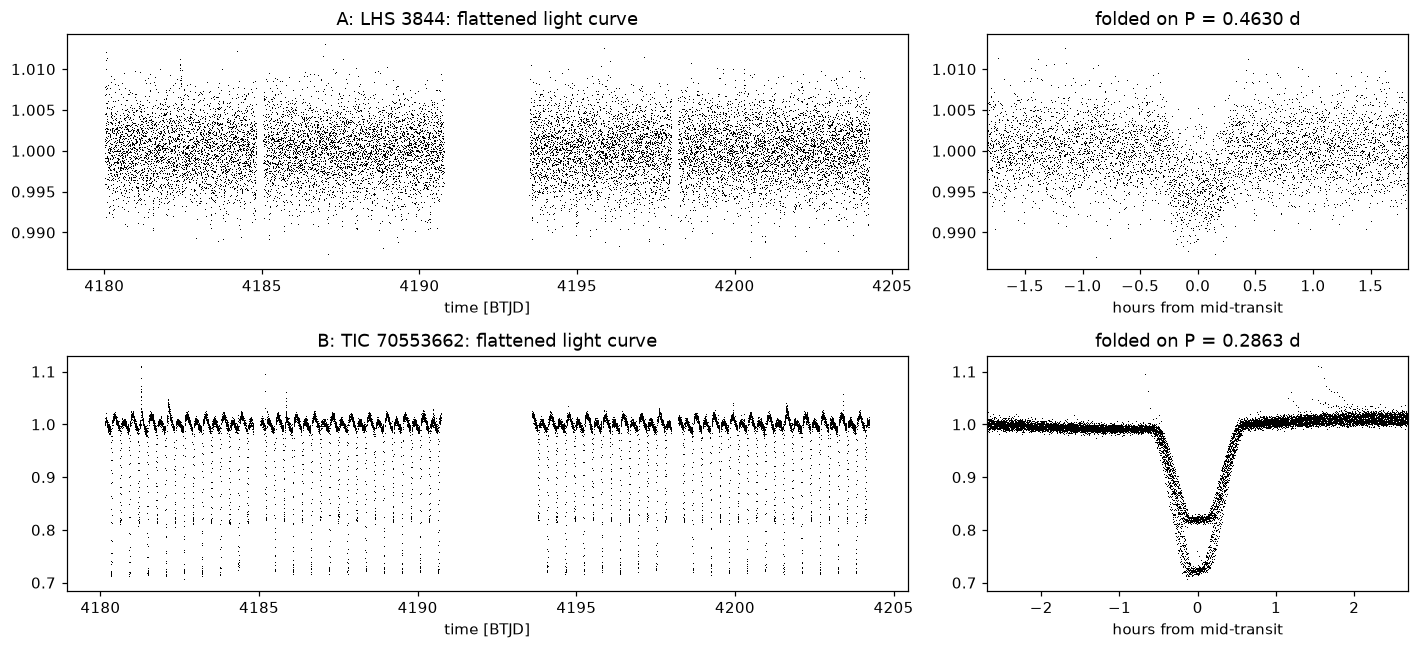

In [3]:
def load_lc(tic_id: int) -> pd.DataFrame:
    return pd.read_parquet(FLAT_DIR / f"{tic_id}.parquet")


def phase_time(t, period, T0):
    '''Time from the nearest predicted mid-transit, in days, in [-P/2, P/2). Transit at 0.'''
    return (t - T0 + 0.5 * period) % period - 0.5 * period


fig, axes = plt.subplots(2, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [2, 1]})
for row, tic in zip(axes, STARS):
    s, lc = search.loc[tic], load_lc(tic)
    row[0].plot(lc.time, lc.flux, ",k")
    row[0].set_title(f"{STARS[tic]}: flattened light curve"); row[0].set_xlabel("time [BTJD]")
    dt = phase_time(lc.time.values, s.period, s.T0) * 24
    row[1].plot(dt, lc.flux, ",k"); row[1].set_xlim(-4 * s.duration_h, 4 * s.duration_h)
    row[1].set_title(f"folded on P = {s.period:.4f} d"); row[1].set_xlabel("hours from mid-transit")
plt.tight_layout()

In the right-hand panels you can already see B's problem: there are **two** lower envelopes
in the fold, one clearly deeper than the other. Half the "transits" are deeper than the
other half. Keep that picture in mind for section 6.

## 2. The false-positive zoo

Before building tests, here is the catalogue of things that produce a periodic, transit-like
dip in a TESS light curve, what gives each one away, and which test in this notebook catches
it. The vetting literature (Kepler Robovetter, Thompson et al. 2018; Coughlin et al. 2016;
TESS DV, Twicken et al. 2018; LEO-vetter, Kunimoto et al.) uses essentially the same list.

| impostor | what it is | its signature | caught by |
|---|---|---|---|
| **Noise** | random fluctuations that happen to line up in the fold | low SDE/SNR | §4: SDE, SNR |
| **Single event** | one outlier, flare residual, or orbit-edge ramp (§5 of the plan) | only 1 transit has data; or one transit carries all the signal | §4: transit count, grid edge; §5: single-event dominance |
| **Instrumental systematics** | TESS fires its thrusters every few days to unload momentum from the reaction wheels ("momentum dumps"); the pointing jumps and the flux glitches | "transits" coincide with dump times | §5: momentum dumps |
| **Eclipsing binary (EB)** | two stars orbiting each other, each eclipsing the other | very deep (often > 5 %); secondary eclipse; V shape | §8 radius, §7 secondary, §10 shape |
| **EB at half its period** | an EB with two similar eclipses per orbit; TLS folds both on top of each other at P/2 | odd and even "transits" have different depths | §6 odd/even |
| **Background / blended EB** | an EB on a *different* star whose light leaks into our aperture (TESS pixels are 21″ wide). Its 30 % eclipse, diluted by our star's light, looks like a 0.3 % transit | centroid moves during transit; duration inconsistent with *our* star; high `contratio` | §10 centroid, contamination; §8 duration |
| **Stellar variability** | spots on a fast-rotating star, or pulsations. The 0.5-day biweight cannot remove variability faster than ~1 day, so TLS fits a "transit" into each dip of a sine wave | TLS period is a harmonic of a strong periodic modulation | §9 variability |

What vetting **cannot** do on its own: prove that a signal *is* a planet. A signal that
passes everything is a *candidate*. Statistical validation (TRICERATOPS), ground-based
photometry and radial velocities come later.

## 3. The noise model: white noise, red noise and the β factor

Almost every test below has the same form: *measure a depth (or a difference of depths) and
divide by its uncertainty*. That ratio is a **significance in σ**. A 3σ difference happens
by chance 0.3 % of the time if the uncertainty is right. So the whole of vetting stands on
one question: **what is the uncertainty of the mean flux over a block of n points?**

**White noise.** If every point has independent noise of standard deviation σ, the mean of
n points has uncertainty σ/√n. This is the textbook answer. With 2-minute cadence, a 30-minute
transit has n = 15 points, so the depth uncertainty is σ/√15 ≈ 0.26 σ.

**Red (correlated) noise.** Real light curves have noise that is correlated over minutes to
hours: residual stellar variability, granulation, pointing jitter, imperfect detrending. Then
averaging n points helps *less* than √n, because neighbouring points share the same error.
If we used σ/√n anyway, we would underestimate every uncertainty, and every test would
report inflated significances. That is how real planets fail the odd/even test.

**The β factor** (Pont, Zucker & Queloz 2006; Winn et al. 2008) is the standard,
cheap correction:

1. Take the out-of-transit flux and cut it into consecutive bins of length equal to the transit
   duration (each bin holds ~n points).
2. Measure the actual scatter of the bin means, σ_dur.
3. Compare with the white-noise prediction σ/√n: $\beta = \sigma_{\rm dur} / (\sigma/\sqrt{n})$, floored at 1.
4. Use $\beta\,\sigma/\sqrt{n}$ as the uncertainty of the mean of n in-transit points.

β = 1 means the noise is white on the transit timescale. β = 2 means the uncertainties are
twice the white-noise ones. **Every significance in this notebook uses this β-corrected
error.**

We use a *robust* standard deviation everywhere (1.4826 × the median absolute deviation),
for the same reason `detrend.py` does: a few leftover outliers should not set the noise level.
For Gaussian data it equals the ordinary standard deviation.

In [4]:
def robust_std(x) -> float:
    '''1.4826 * MAD: equals the standard deviation for Gaussian data, ignores outliers.'''
    x = np.asarray(x)
    return float(1.4826 * np.median(np.abs(x - np.median(x))))


def noise_model(t, y, oot, dur) -> dict:
    '''Point scatter and the red-noise factor beta on the timescale `dur` (days).

    oot = boolean mask of out-of-transit points (we never measure noise on the transits).
    '''
    sigma = robust_std(y[oot])
    tb, yb = t[oot], y[oot]
    edges = np.arange(tb.min(), tb.max() + dur, dur)
    idx = np.digitize(tb, edges)
    cnt = np.bincount(idx)
    tot = np.bincount(idx, yb)
    full = cnt >= max(3, 0.5 * np.median(cnt[cnt > 0]))  # skip bins cut by gaps
    n_dur = float(np.median(cnt[full]))
    sigma_dur = robust_std(tot[full] / cnt[full])
    beta = max(1.0, sigma_dur / (sigma / np.sqrt(n_dur)))
    return {"sigma": sigma, "sigma_dur": sigma_dur, "n_dur": n_dur, "beta": beta}


def depth_and_err(y, mask, noise) -> tuple[float, float]:
    '''Depth (1 - mean flux) of the points in `mask` and its beta-corrected uncertainty.'''
    n = int(mask.sum())
    if n == 0:
        return np.nan, np.nan
    return 1 - float(y[mask].mean()), noise["beta"] * noise["sigma"] / np.sqrt(n)


def prepare(tic_id):
    '''Everything the tests share for one star: light curve arrays, ephemeris, masks, noise.'''
    s, lc = search.loc[tic_id], load_lc(tic_id)
    t, y = lc["time"].values, lc["flux"].values
    dur = s.duration_h / 24  # days
    dt = phase_time(t, s.period, s.T0)
    in_tr = np.abs(dt) < dur / 2  # inside the transit
    oot = np.abs(dt) > dur  # safely outside (1 duration margin each side)
    return dict(tic_id=tic_id, s=s, t=t, y=y, dur=dur, dt=dt, in_tr=in_tr, oot=oot,
                noise=noise_model(t, y, oot, dur))


prep = {tic: prepare(tic) for tic in STARS}
pd.DataFrame({STARS[k]: v["noise"] for k, v in prep.items()})

,A: LHS 3844,B: TIC 70553662
sigma,0.003246,0.009624
sigma_dur,0.000941,0.009213
n_dur,14.000000,20.000000
beta,1.084993,4.281343


- `sigma`: per-point scatter (relative flux; multiply by 10⁶ for ppm). B's is larger
  because its fold has more stellar structure left in it.
- `n_dur`: points per transit duration. A: 2-min SPOC cadence, 0.46 h → ~14 points.
- `beta`: A is ≈ 1, so its noise is white on transit timescales. **B has β ≈ 4**: there
  is variability left on hour timescales (the ellipsoidal/reflection modulation of a
  close binary). Its uncertainties will be ×4 the naive ones, and it will *still* fail.

The plot below shows how β is defined. It plots the scatter of bin means against bin size.
White noise follows the dashed σ/√n line. Red noise bends above it. A follows the line
almost exactly. B's scatter barely decreases with binning, because what we call "noise" there
is mostly the binary's smooth, hour-scale modulation, which averaging cannot remove.

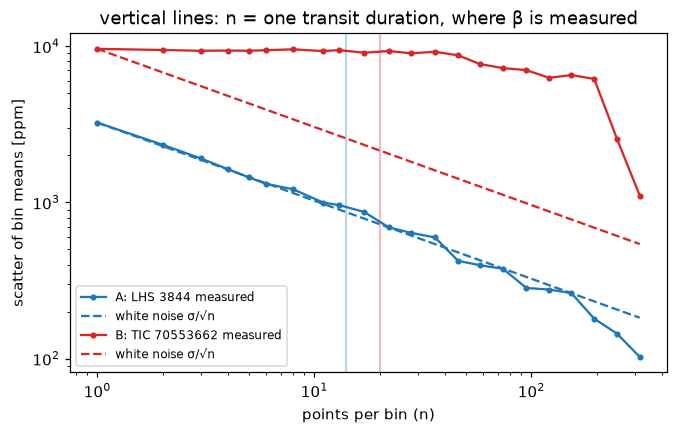

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for tic, color in zip(STARS, ["C0", "C3"]):
    p = prep[tic]
    tb, yb = p["t"][p["oot"]], p["y"][p["oot"]]
    cadence = np.median(np.diff(tb))
    sizes = np.unique(np.logspace(0, 2.5, 25).astype(int))
    rms = []
    for n in sizes:
        edges = np.arange(tb.min(), tb.max(), n * cadence)
        idx = np.digitize(tb, edges); cnt = np.bincount(idx); tot = np.bincount(idx, yb)
        full = cnt >= 0.8 * n
        rms.append(robust_std(tot[full] / cnt[full]))
    ax.loglog(sizes, np.array(rms) * 1e6, "o-", color=color, ms=3, label=f"{STARS[tic]} measured")
    ax.loglog(sizes, p["noise"]["sigma"] / np.sqrt(sizes) * 1e6, "--", color=color, label="white noise σ/√n")
    ax.axvline(p["noise"]["n_dur"], color=color, alpha=0.3)
ax.set_xlabel("points per bin (n)"); ax.set_ylabel("scatter of bin means [ppm]")
ax.set_title("vertical lines: n = one transit duration, where β is measured"); ax.legend(fontsize=8)

## 4. Group A — tests that need only the search table

These four use columns `search.py` already stored, so they are vectorised and instant. In
`vet.py` they also work as a **cheap pre-filter**: a star that fails them all does not need
its light curve opened. (We still record every result, but later tests may be skipped and
left as NaN for stars that are obviously noise. More on that in the checklist.)

All thresholds are in one dictionary. Each one is explained where it is used.

In [6]:
THRESH = dict(
    sde_min=9.0,              # §4.1  TLS white-noise FAP ~1e-4; plan §7
    snr_min=7.0,              # §4.2  Kepler/TESS convention (7.1 sigma)
    n_transits_min=2,         # §4.3  periodicity needs at least two events
    grid_edge_frac=0.98,      # §4.4  period within 2 % of period_max = peak at the grid edge
    survive_frac=0.5,         # §5    the signal must keep >= 50 % of its expected SNR after dropping suspect transits
    dump_window_d=0.25,       # §5.3  +- 0.25 d around a momentum dump (plus half a transit) = biweight half-window
    local_noise_d=0.5,        # §5.1  per-transit noise from out-of-transit points within +- 0.5 d
    edge_coverage_min=0.5,    # §5.3  a transit needs >= 50 % of the expected points on each side
    scatter_ratio_max=2.0,    # §5.3  in-transit scatter (central half) / local scatter above this = noisy transit
    odd_even_sigma_max=3.0,   # §6
    secondary_snr_max=5.0,    # §7    5 sigma because we search many phases (look-elsewhere)
    dur_ratio_min=1 / 3,      # §8.1  observed / expected central-transit duration
    dur_ratio_max=3.0,
    rp_earth_max=16.8,        # §8.2  1.5 Jupiter radii
    var_fap_max=1e-3,         # §9    the periodogram peak must be significant ...
    var_harmonic_tol=1.0,     # §9    ... at a harmonic of the TLS frequency, within 1/baseline ...
    var_harmonic_n_max=10,
    var_amp_frac_max=0.15,    # §9    ... and its semi-amplitude >= 15 % of the transit depth
    variable_amp_frac=0.3,    # §10.4 soft: any significant modulation >= 30 % of the depth
    v_shape_max=0.3,          # §10.1 soft: flat-bottom fraction T23/T14 below this = V-shaped
    centroid_sigma_max=3.0,   # §10.2 soft
    contratio_max=0.5,        # §10.3 soft
)

### 4.1 SDE ≥ 9

SDE (from the search walkthrough §2) measures how far the best period stands above the
other periods in the periodogram, in units of the periodogram's own scatter. Hippke & Heller
(2019) calibrated it on white-noise simulations: **SDE = 9 corresponds to a false-alarm
probability of ≈ 10⁻⁴ per light curve**. With ~5,000 light curves, that still means ~0.5
pure-noise false alarms per sector, and real noise is red, so the real number is higher. That
is why SDE is only the *first* gate.

### 4.2 SNR ≥ 7

TLS's `snr` is the transit depth divided by its uncertainty, combining all transits:
$\text{SNR} = \frac{\delta}{\sigma}\sqrt{N_{\rm in}}$, where $N_{\rm in}$ is the total
number of in-transit points. SDE asks "is this period special?". SNR asks "is the dip
itself significant?". They usually agree, but not always: an SDE peak can come from a broad
low-amplitude feature with a low SNR. The 7.1σ threshold comes from Kepler (Jenkins et al.
2002): with ~10¹² independent trials in a Kepler-like search, 7.1σ gives about one false
alarm from Gaussian noise. TESS uses the same 7.1 for TCEs. We round it to 7.

### 4.3 At least two transits with data

One dip is not evidence of periodicity. TLS predicts `transit_count` transits within the
baseline, and `distinct_transit_count` is how many have data points. The other ones fell in
the mid-sector gap or in the orbit-edge trims.

### 4.4 The period is not at the edge of the grid

From the search walkthrough §4: when the best period sits at `period_max` (= half the
baseline) and its uncertainty is infinite, the "periodogram peak" is just the edge of the
grid. This is the signature of a single event whose "second transit" TLS hides in the gap.
`detrend.py`'s edge trim removed most of these, but the test stays as a safety net.

In [7]:
def test_search_stats(s) -> dict:
    '''Group A: uses only the TLS row from the search table.'''
    at_edge = (s.period >= THRESH["grid_edge_frac"] * s.period_max) or not np.isfinite(s.period_unc)
    return {
        "pass_sde": bool(s.SDE >= THRESH["sde_min"]),
        "pass_snr": bool(s.snr >= THRESH["snr_min"]),
        "pass_n_transits": bool(s.distinct_transit_count >= THRESH["n_transits_min"]),
        "pass_grid_edge": bool(not at_edge),
    }


pd.DataFrame({STARS[t]: test_search_stats(search.loc[t]) for t in STARS})

,A: LHS 3844,B: TIC 70553662
pass_sde,True,True
pass_snr,True,True
pass_n_transits,True,True
pass_grid_edge,True,True


Both pass, as expected: Group A only removes noise and single events. To see how much
work these four cheap tests do, apply them to the whole search table at once. This is the
only sector-wide computation in this notebook. It tells us how many light curves the
expensive tests in `vet.py` will have to open.

In [8]:
A = pd.DataFrame({
    "sde": ok.SDE >= THRESH["sde_min"],
    "snr": ok.snr >= THRESH["snr_min"],
    "n_transits": ok.distinct_transit_count >= THRESH["n_transits_min"],
    "grid_edge": (ok.period < THRESH["grid_edge_frac"] * ok.period_max) & np.isfinite(ok.period_unc),
})
funnel = {"all stars": len(A)}
running = pd.Series(True, index=A.index)
for name in A.columns:
    running &= A[name]
    funnel[f"... and pass_{name}"] = int(running.sum())
pd.Series(funnel, name="stars left")

all stars                  4693
... and pass_sde            554
... and pass_snr            402
... and pass_n_transits     351
... and pass_grid_edge      349
Name: stars left, dtype: int64

About 350 signals survive the cheap tests. The rest of the notebook is about what removes
the rest, without removing the planets.

## 5. Group B — looking at the transits one by one

TLS reports a *combined* signal over all transits. Several false positives hide inside that
average: one huge event plus noise, or "transits" that all fall on momentum dumps. So
the next step is to measure every transit separately.

### 5.1 Per-transit depths

For each predicted transit (epoch k, mid-time $t_k = T_0 + kP$) take the points within
±duration/2, and compute their depth $\delta_k$ and uncertainty $\epsilon_k = \beta\sigma_k/\sqrt{n_k}$.

**Which σ?** Not the global scatter of the whole sector, but the **local** scatter $\sigma_k$ of
the out-of-transit points within ±0.5 d of that transit. TESS noise is far from uniform: right
after a data gap, during scattered-light episodes, or on a ramp the detrending could not
follow, the scatter can be several times higher. A transit that falls there should count for
less. With the global σ it borrowed the quiet noise level of the rest of the sector, and a
noise spike looked like a significant transit (one of the first-run candidates did exactly
that, see §12.1). We floor $\sigma_k$ at half the global σ, so a few unusually quiet points
cannot inflate a transit's weight.

To **combine** transits, use the inverse-variance weighted mean. It is the
minimum-variance unbiased combination of independent measurements:

$$\bar\delta = \frac{\sum_k \delta_k/\epsilon_k^2}{\sum_k 1/\epsilon_k^2}, \qquad
\epsilon_{\bar\delta} = \Big(\sum_k 1/\epsilon_k^2\Big)^{-1/2}, \qquad
\text{SNR} = \bar\delta / \epsilon_{\bar\delta}.$$

This SNR is our own version of TLS's `snr`, and it uses the β-corrected errors. (Kepler
called the single-transit value *SES*, single event statistic, and the combined one *MES*,
multiple event statistic.)

In [9]:
def per_transit(p) -> pd.DataFrame:
    '''One row per transit epoch that has in-transit data: depth, LOCAL error, SNR, data coverage.'''
    s, t, y, dur, noise = p["s"], p["t"], p["y"], p["dur"], p["noise"]
    epoch = np.round((t - s.T0) / s.period).astype(int)
    cadence = np.median(np.diff(t))
    side = max(dur, 1 / 24)  # the window checked on each side of the transit (§5.3)
    rows = []
    for k in np.unique(epoch[p["in_tr"]]):
        m = p["in_tr"] & (epoch == k)
        tm = s.T0 + k * s.period
        near = p["oot"] & (np.abs(t - tm) < THRESH["local_noise_d"])
        sig_k = robust_std(y[near]) if near.sum() >= 30 else noise["sigma"]
        sig_k = max(sig_k, 0.5 * noise["sigma"])
        n = int(m.sum())
        d, e = 1 - y[m].mean(), noise["beta"] * sig_k / np.sqrt(n)
        pre = ((t > tm - dur / 2 - side) & (t < tm - dur / 2)).sum() * cadence / side
        post = ((t > tm + dur / 2) & (t < tm + dur / 2 + side)).sum() * cadence / side
        core = m & (np.abs(t - tm) < dur / 4)  # central half of the transit: no ingress/egress gradient
        ratio = robust_std(y[core]) / sig_k if core.sum() >= 6 else np.nan
        rows.append((k, tm, n, d, e, sig_k, min(pre, post), ratio))
    pt = pd.DataFrame(rows, columns=["epoch", "t_mid", "n", "depth", "err", "sigma_local", "coverage", "scatter_ratio"])
    pt["snr"] = pt["depth"] / pt["err"]
    return pt


def combine(pt) -> tuple[float, float, float]:
    '''Inverse-variance weighted depth, its error and SNR over the rows of `pt`.'''
    if len(pt) == 0:
        return np.nan, np.nan, np.nan
    w = 1 / pt["err"] ** 2
    d = float((pt["depth"] * w).sum() / w.sum())
    e = float(1 / np.sqrt(w.sum()))
    return d, e, d / e


for tic in STARS:
    prep[tic]["pt"] = per_transit(prep[tic])
    d, e, snr = combine(prep[tic]["pt"])
    print(f"{STARS[tic]:18s} {len(prep[tic]['pt'])} transits with data | combined depth "
          f"{d*1e6:8.0f} +- {e*1e6:5.0f} ppm | SNR {snr:6.1f} (TLS snr {search.loc[tic].snr:6.1f})")
prep[PLANET]["pt"].head(8)

A: LHS 3844        47 transits with data | combined depth     4278 +-   140 ppm | SNR   30.6 (TLS snr   32.4)
B: TIC 70553662    72 transits with data | combined depth   194583 +-  1059 ppm | SNR  183.7 (TLS snr 1037.1)


,epoch,t_mid,n,depth,err,sigma_local,coverage,scatter_ratio,snr
0,0,4180.149421,13,0.003133,0.000983,0.003267,1.000047,1.203996,3.186939
1,1,4180.612374,14,0.002614,0.000966,0.003332,1.000047,0.531983,2.705363
2,2,4181.075326,14,0.003669,0.001005,0.003466,1.000047,1.845210,3.650926
3,3,4181.538279,13,0.006305,0.000997,0.003312,1.000047,1.159449,6.326427
4,4,4182.001231,14,0.004447,0.000980,0.003380,1.000047,0.474410,4.536986
5,5,4182.464184,14,0.002771,0.000995,0.003431,1.000047,0.850743,2.785609
6,6,4182.927137,14,0.003980,0.000916,0.003160,1.000047,0.652503,4.344238
7,7,4183.390089,13,0.005428,0.001019,0.003386,1.000047,1.007439,5.327530


Our combined SNR for A agrees with TLS's (31 vs 32). B's is much smaller than TLS's,
because β ≈ 4 inflates its errors and the binary's out-of-eclipse modulation inflates its
point scatter. It is still in the hundreds, though: B is not a weak signal.

Plot the per-transit depths over time. A planet should give a flat row of points at the same
depth, scattered within their error bars. The dashed vertical lines are the momentum dumps
(found in §5.3).

### 5.2 Momentum dumps: where they come from

TESS keeps its pointing with reaction wheels. Solar radiation pressure slowly spins them up,
and every few days the spacecraft fires thrusters to unload ("dump") the accumulated momentum.
During a dump the pointing jumps, and the flux of the stars in the aperture can glitch for an
hour or more. The cadences *during* the dump are flagged and were already removed in
`detrend.py`, but the flux on either side can still be off.

The dump times are **the same for every star in the sector** (it is the whole spacecraft).
They are recorded in the `QUALITY` column of every light-curve file as **bit 6 (value
32)**, "reaction wheel desaturation event". Both SPOC and QLP use the same bit. So we read
the raw FITS of a handful of stars with *no* quality mask, collect the flagged times, and
merge times closer than 0.1 d. `vet.py` does this once per sector.

In [10]:
def momentum_dumps(manifest: pd.DataFrame, n_files: int = 20, seed: int = 0) -> np.ndarray:
    '''Times (BTJD) of reaction-wheel desaturations, from QUALITY bit 6 (value 32) of raw files.'''
    files = manifest[manifest["status"] == "ok"]["file_path"].sample(n_files, random_state=seed)
    times = []
    for f in files:
        d = fits.getdata(ROOT / f, 1)
        q = d["QUALITY"].astype(np.int64)
        times.append(d["TIME"][((q & 32) > 0) & np.isfinite(d["TIME"])])
    times = np.sort(np.concatenate(times))
    if len(times) == 0:
        return times
    groups = np.split(times, np.where(np.diff(times) > 0.1)[0] + 1)  # one dump spans several cadences
    return np.array([g.mean() for g in groups])


DUMPS = momentum_dumps(manifest)
print("momentum dumps, sector", SECTOR, "[BTJD]:", np.round(DUMPS, 3))

momentum dumps, sector 104 [BTJD]: [4178.585 4185.04  4191.988 4198.203]


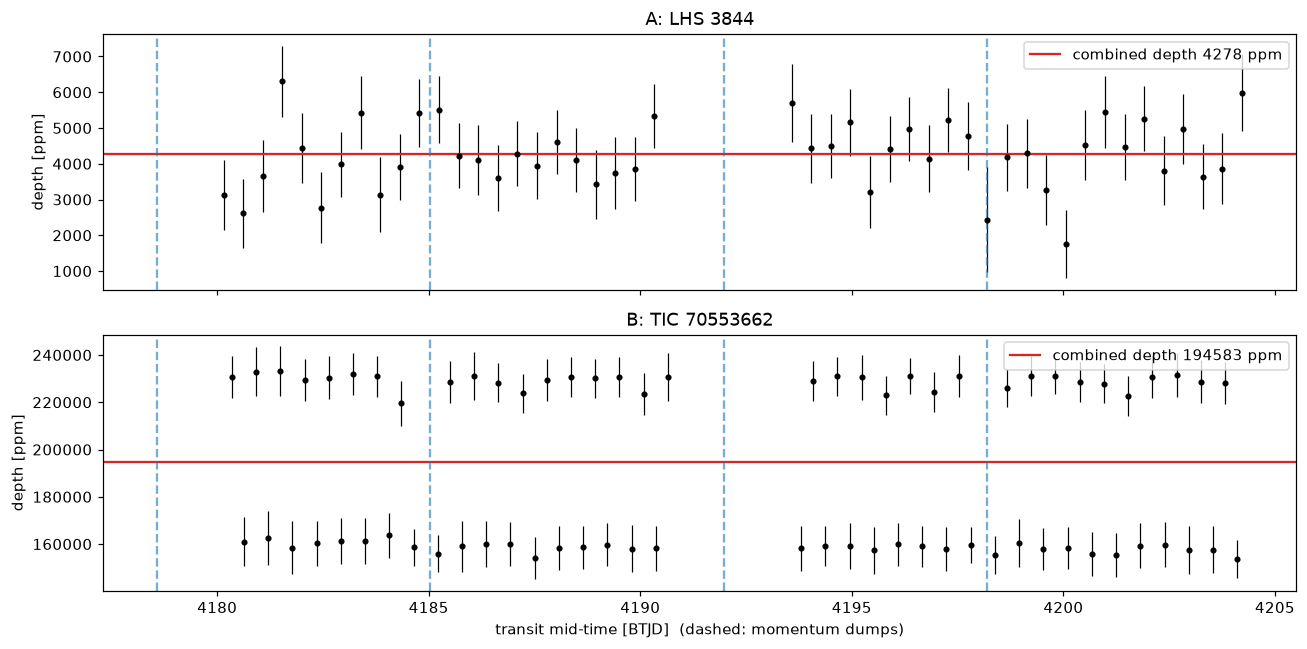

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, tic in zip(axes, STARS):
    pt = prep[tic]["pt"]
    ax.errorbar(pt.t_mid, pt.depth * 1e6, pt.err * 1e6, fmt="o", ms=3, color="k", elinewidth=0.8)
    d, e, _ = combine(pt)
    ax.axhline(d * 1e6, color="C3", label=f"combined depth {d*1e6:.0f} ppm")
    for td in DUMPS:
        ax.axvline(td, color="C0", ls="--", alpha=0.6)
    ax.set_ylabel("depth [ppm]"); ax.set_title(STARS[tic]); ax.legend(loc="upper right")
axes[1].set_xlabel("transit mid-time [BTJD]  (dashed: momentum dumps)")
plt.tight_layout()

A (top): a flat row at ~4,300 ppm, with every transit consistent with the combined value.
Look at B (bottom): the depths **alternate between two levels**. That is the odd/even
effect, and §6 turns it into a number.

### 5.3 Four tests built on the per-transit table

All four ask the same question: **does the signal survive if we throw away the transits
we have reason to distrust?**

If all N transits are equally deep, removing m of them should reduce the combined SNR by a
factor $\sqrt{(N-m)/N}$, because SNR grows as √N. So we compare the SNR we actually get
after removing them with that expectation:

$$\text{survival} = \frac{\text{SNR}_{\rm kept}}{\text{SNR}_{\rm all}\sqrt{N_{\rm kept}/N}}$$

≈ 1 means the removed transits were typical. ≪ 1 means the removed transits carried the
signal. We fail the test if survival < 0.5.

How many transits must be *left*? For the momentum-dump test, at least 2: a signal with only one
transit away from the dumps has no periodic evidence that is not suspect. For the single-event
test, just 1: a 2-transit planet loses its stronger transit and must keep half its expected SNR
in the other one. (The first version required 2 left in both tests. That silently rejected
**every** 2-transit signal, i.e. every planet with P ≳ 8 d. The injection-recovery run in
notebook 8 exposed it.)

- **Single-event dominance**: remove the *single strongest* transit. This catches one
  large outlier (a flare residual, a cosmic ray, a pointing glitch) that TLS folded together
  with noise. Kepler's Robovetter has an equivalent test (the max-SES-to-MES comparison).
- **Momentum dumps**: remove every transit whose mid-time is within ±(0.25 d + duration/2) of
  a dump. Why 0.25 d? A dump often leaves a small *step* in the flux, and the 0.5-day
  biweight smooths a step over ±window/2 = ±0.25 d. Inside that zone the flattened flux is
  distorted (the same reasoning as the 0.25-d orbit-edge trim in `detrend.py`). The plan's literal
  rule, "no transit within ±0.1 d of a dump", would also be wrong for short periods. LHS 3844 b
  transits every 11 hours, so with 4 dumps *some* transit is always near one by chance. What
  matters is whether the signal depends on those transits.
- **Data edges**: a transit needs data on **both** sides. For each transit we count the
  points in a window of max(duration, 1 h) just before ingress and just after egress, and
  compare with what the cadence predicts (`coverage`, 0 to 1). If either side has less than
  half, the transit sits at the edge of a data segment: right after a gap, at an orbit start, or
  just before a dump where data was removed. That is where the flattened flux is least
  trustworthy, and where a ramp or step can imitate half a transit. Such transits are
  dropped, and the signal must survive (≥ 2 transits left, like the dump test).
- **Transit noise**: a real transit shifts the in-transit points *down* but leaves their
  scatter unchanged. A burst of noise (pointing jitter, a glitch) *inflates* the scatter, and
  its mean can happen to be low. We compare the robust scatter of the points in the central
  half of each transit (no ingress/egress gradient) with the local out-of-transit scatter.
  Transits above 2× are dropped and the signal must survive. In sector 104 every known planet
  stays below 1.7×, while the glitch-driven candidate in notebook 7 (TIC 394134586) reaches 3.9×.

In [12]:
def survival(pt, drop, min_keep=1) -> tuple[float, int]:
    '''SNR kept after removing the rows in `drop`, relative to the sqrt(N) expectation (0 if < min_keep left).'''
    keep = pt[~drop]
    if len(keep) < min_keep:
        return 0.0, len(keep)
    _, _, snr_all = combine(pt)
    _, _, snr_keep = combine(keep)
    return float(snr_keep / (snr_all * np.sqrt(len(keep) / len(pt)))), len(keep)


def test_single_event(p) -> dict:
    pt = p["pt"]
    drop = pt.index == pt["snr"].idxmax()
    surv, _ = survival(pt, drop)
    return {"max_ses_frac": float(pt["snr"].max() / combine(pt)[2]),  # strongest transit's share of the total SNR
            "single_event_survival": surv,
            "pass_single_event": bool(surv >= THRESH["survive_frac"])}


def test_momentum_dumps(p, dumps) -> dict:
    pt = p["pt"]
    window = THRESH["dump_window_d"] + p["dur"] / 2
    near = np.array([np.min(np.abs(tm - dumps)) < window for tm in pt["t_mid"]]) if len(dumps) else np.zeros(len(pt), bool)
    if not near.any():
        return {"n_near_dump": 0, "dump_survival": 1.0, "pass_momentum_dump": True}
    surv, _ = survival(pt, near, min_keep=THRESH["n_transits_min"])
    return {"n_near_dump": int(near.sum()), "dump_survival": surv,
            "pass_momentum_dump": bool(surv >= THRESH["survive_frac"])}


def test_data_edges(p) -> dict:
    pt = p["pt"]
    edge = (pt["coverage"] < THRESH["edge_coverage_min"]).to_numpy()
    if not edge.any():
        return {"n_edge": 0, "edge_survival": 1.0, "pass_data_edges": True}
    surv, _ = survival(pt, edge, min_keep=THRESH["n_transits_min"])
    return {"n_edge": int(edge.sum()), "edge_survival": surv,
            "pass_data_edges": bool(surv >= THRESH["survive_frac"])}


def test_transit_noise(p) -> dict:
    pt = p["pt"]
    noisy = (pt["scatter_ratio"] > THRESH["scatter_ratio_max"]).to_numpy()
    if not noisy.any():
        return {"n_noisy": 0, "noisy_survival": 1.0, "pass_transit_noise": True}
    surv, _ = survival(pt, noisy, min_keep=THRESH["n_transits_min"])
    return {"n_noisy": int(noisy.sum()), "noisy_survival": surv,
            "pass_transit_noise": bool(surv >= THRESH["survive_frac"])}


pd.DataFrame({STARS[t]: {**test_single_event(prep[t]), **test_momentum_dumps(prep[t], DUMPS),
                         **test_data_edges(prep[t]), **test_transit_noise(prep[t])} for t in STARS})

,A: LHS 3844,B: TIC 70553662
max_ses_frac,0.206672,0.163171
single_event_survival,0.99131,0.993868
pass_single_event,True,True
n_near_dump,2,2
dump_survival,1.002878,1.003141
pass_momentum_dump,True,True
n_edge,1,0
edge_survival,1.010173,1.0
pass_data_edges,True,True
n_noisy,0,0


- `max_ses_frac`: the strongest single transit's SNR divided by the combined SNR. For N
  equal transits it is ≈ 1/√N (≈ 0.15 for 47 transits; the *strongest* of 47 noisy
  transits sits a bit above that, 0.21 for A). A value near 1 means one event *is* the signal.
- `single_event_survival` ≈ 1 for both: no single transit dominates either signal.
- LHS 3844 has `n_near_dump = 2`, two transits that by chance fall next to dumps, and
  removing them changes nothing (survival ≈ 1). The literal rule from the plan would have
  rejected a confirmed planet here.
- `n_edge = 1` for LHS 3844: one transit sits at the edge of a data segment. Dropping it
  changes nothing either (`edge_survival` ≈ 1). `coverage` in the per-transit table above is
  ≈ 1 for the transits in continuous data.

## 6. Odd/even depth test

**The impostor.** An eclipsing binary made of two similar stars produces **two eclipses per
orbit**: the primary (the hotter star is eclipsed) and the secondary, half an orbit later
for a circular orbit. If the two eclipses have similar depths, TLS sees a dip every P/2,
folds them all together and reports **half the true period**. Every other "transit" is then
really the other eclipse. Numbering transits by epoch k, the odd k are one eclipse and the
even k are the other.

**The test.** A planet blocks the same star every time, so odd and even transits must have
the same depth. Measure both (combining all in-transit points of odd epochs, then of even
epochs) and compute the difference in σ:

$$\Delta_{\rm oe} = \frac{|\delta_{\rm odd} - \delta_{\rm even}|}{\sqrt{\epsilon_{\rm odd}^2 + \epsilon_{\rm even}^2}}$$

Fail if Δ > 3σ. TLS computes the same quantity (`odd_even_mismatch`) but with white-noise
errors. We recompute it with β because, as we found while preparing this notebook, the
confirmed planet TOI-177 b reaches 4.3σ without β and 2.6σ with it. The white-noise version
is too strict.

In [13]:
def test_odd_even(p) -> dict:
    s, t, y = p["s"], p["t"], p["y"]
    epoch = np.round((t - s.T0) / s.period).astype(int)
    d_odd, e_odd = depth_and_err(y, p["in_tr"] & (epoch % 2 == 1), p["noise"])
    d_even, e_even = depth_and_err(y, p["in_tr"] & (epoch % 2 == 0), p["noise"])
    sig = abs(d_odd - d_even) / np.hypot(e_odd, e_even)
    return {"depth_odd_ppm": d_odd * 1e6, "depth_even_ppm": d_even * 1e6, "odd_even_sigma": sig,
            "pass_odd_even": bool(not (sig > THRESH["odd_even_sigma_max"]))}  # NaN (no odd or no even) -> pass


res = pd.DataFrame({STARS[t]: test_odd_even(prep[t]) for t in STARS})
res.loc["TLS odd_even_mismatch (white noise)"] = [search.loc[t].odd_even_mismatch for t in STARS]
res

,A: LHS 3844,B: TIC 70553662
depth_odd_ppm,4318.728576,158650.719252
depth_even_ppm,4228.754662,228885.276989
odd_even_sigma,0.32117,32.439335
pass_odd_even,True,False
TLS odd_even_mismatch (white noise),0.243178,22.275485


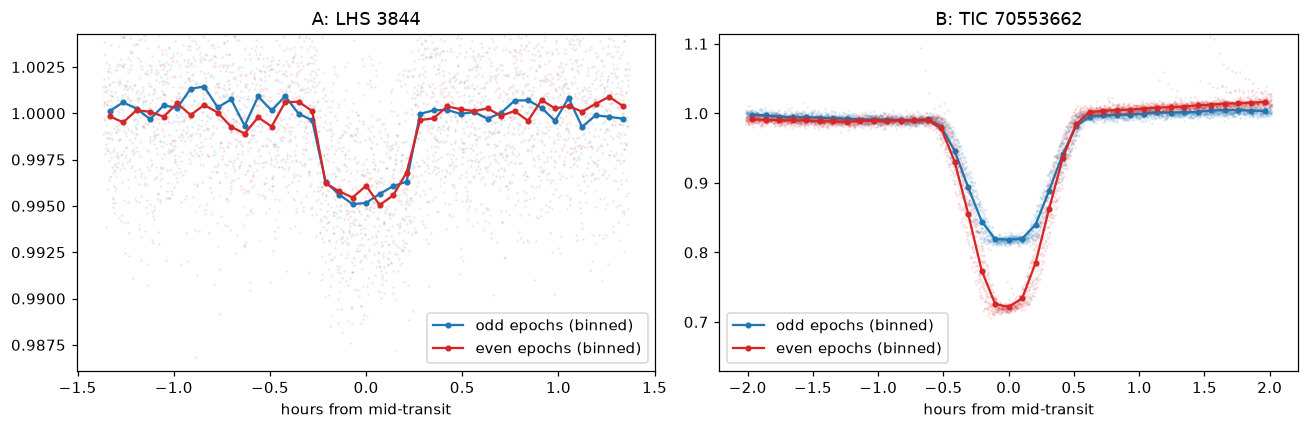

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, tic in zip(axes, STARS):
    p = prep[tic]; s = p["s"]
    epoch = np.round((p["t"] - s.T0) / s.period).astype(int)
    x = p["dt"] * 24
    for parity, color, lab in [(1, "C0", "odd"), (0, "C3", "even")]:
        m = (epoch % 2 == parity) & (np.abs(x) < 3 * s.duration_h)
        bins = np.linspace(-3 * s.duration_h, 3 * s.duration_h, 40)
        idx = np.digitize(x[m], bins)
        b = [p["y"][m][idx == i].mean() if np.any(idx == i) else np.nan for i in range(1, len(bins))]
        ax.plot(x[m], p["y"][m], ".", ms=1, color=color, alpha=0.15)
        ax.plot(0.5 * (bins[1:] + bins[:-1]), b, "o-", ms=3, color=color, label=f"{lab} epochs (binned)")
    ax.set_title(STARS[tic]); ax.set_xlabel("hours from mid-transit"); ax.legend()
    lo = np.percentile(p["y"][p["in_tr"]], 2); ax.set_ylim(lo - 0.3 * (1 - lo), 1 + 0.4 * (1 - lo))
plt.tight_layout()

For A, the odd and even curves lie on top of each other. For B they are two clearly different
eclipses: averaged over the transit window ~23 % and ~16 % deep (deeper still at minimum). The true orbital period of B is **2 × 0.286 = 0.573 days**, and
B is a binary of two M dwarfs. Odd/even catches B at >30σ even after the ×4 β inflation.

## 7. Secondary eclipse test

**The physics.** When the companion passes *behind* the star, its own light is blocked. The
depth of that "secondary eclipse" is roughly the companion's share of the total light:

- **A planet** emits almost nothing in the TESS band compared with its star. Even for a
  hot Jupiter the secondary is ~10–100 ppm, and for a small planet around an M dwarf it is
  ≪ our noise. **We expect to see nothing.**
- **A stellar companion** is a star. Its secondary eclipse can be anything from a few % of the
  primary depth to equal to it.

For a circular orbit the secondary is at phase 0.5. For an **eccentric** orbit it can be
anywhere, so instead of looking only at phase 0.5 we **scan every phase**: slide a box one
transit-duration wide across the folded light curve (excluding ±1.5 durations around the
transit itself), and record the most significant dip.

**Why 5σ and not 3σ:** we test ~P/duration × 4 positions. The more places we look, the
more likely one of them shows a 3σ fluctuation by chance (the *look-elsewhere effect*). For
a 12-day period and a 1-hour transit there are ~300 independent positions, and the largest
of 300 Gaussian draws is typically ~3σ. 5σ keeps the false-rejection rate of real planets low.

In [15]:
def test_secondary(p) -> dict:
    s, y, dt, dur, noise = p["s"], p["y"], p["dt"], p["dur"], p["noise"]
    P = s.period
    best = {"secondary_snr": 0.0, "secondary_depth_ppm": np.nan, "secondary_phase": np.nan}
    scan = []
    for c in np.arange(-P / 2, P / 2, dur / 4):
        if abs(c) < 1.5 * dur or P - abs(c) < 1.5 * dur:  # skip the primary transit itself
            continue
        dist = np.abs((dt - c + P / 2) % P - P / 2)  # distance to the box centre, wrapping around the phase
        m = dist < dur / 2
        if m.sum() < 3:
            continue
        d, e = depth_and_err(y, m, noise)
        scan.append(((c / P) % 1, d / e))
        if d / e > best["secondary_snr"]:
            best = {"secondary_snr": d / e, "secondary_depth_ppm": d * 1e6, "secondary_phase": (c / P) % 1}
    best["pass_secondary"] = bool(best["secondary_snr"] < THRESH["secondary_snr_max"])
    p["secondary_scan"] = np.array(sorted(scan))  # (phase, sigma) sorted by phase; kept for plotting only
    return best


pd.DataFrame({STARS[t]: test_secondary(prep[t]) for t in STARS})

,A: LHS 3844,B: TIC 70553662
secondary_snr,1.107625,9.093172
secondary_depth_ppm,157.314935,9859.722478
secondary_phase,0.372379,0.842177
pass_secondary,True,False


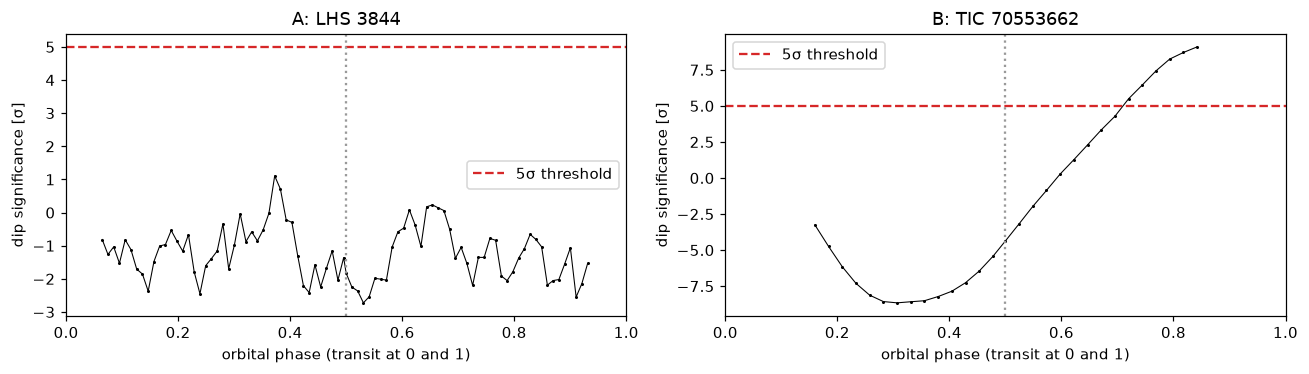

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, tic in zip(axes, STARS):
    sc = prep[tic]["secondary_scan"]
    ax.plot(sc[:, 0], sc[:, 1], ".-", ms=2, lw=0.7, color="k")
    ax.axhline(THRESH["secondary_snr_max"], color="C3", ls="--", label="5σ threshold")
    ax.axvline(0.5, color="0.6", ls=":"); ax.set_xlim(0, 1)
    ax.set_xlabel("orbital phase (transit at 0 and 1)"); ax.set_ylabel("dip significance [σ]")
    ax.set_title(STARS[tic]); ax.legend()
plt.tight_layout()

A: the scan is pure noise, within ±3σ everywhere.

B fails, but **look at where**: the maximum (9σ, ~1 %) is at phase 0.84, right at the edge
of the window we excluded around the primary. That is not a second eclipse. It is the
pre-eclipse side of the fold, where the binary's out-of-eclipse modulation keeps the flux
~1 % low (compare the left and right shoulders of B's fold in §6). The rejection is still
correct, because a planet's fold must be flat outside the transit. But it shows that **a test
can fire for a reason other than its name**, so read the metric (`secondary_phase`,
`secondary_depth_ppm`), not just the verdict.

B's real secondary eclipse is *not* found by this test. At the wrong (half) period it is folded *onto* the primary, which is exactly what
the odd/even test measures. The two tests complement each other: odd/even catches EBs with
two similar eclipses found at P/2, and the secondary scan catches EBs found at the right
period, including eccentric ones (TIC 371997949 in §12 has its secondary at phase ≈ 0.55).

## 8. Tests that use the star

The search table has the transit; the target table (step 1) has the star: radius R★ and
mass M★ from the TIC. Two physical checks follow.

### 8.1 Transit duration vs Kepler's third law

**Derivation.** A planet on a circular orbit of period P around a star of mass M★ has
orbital radius $a$ given by Kepler's third law,

$$a^3 = \frac{G M_\star P^2}{4\pi^2}.$$

It moves at constant speed along a circle of circumference 2πa. A central transit (the
planet crosses the middle of the disk, impact parameter b = 0) lasts while the planet's
projected position is within $R_\star + R_p$ of the star's centre. The planet covers an
orbital angle of $2\arcsin\!\big((R_\star+R_p)/a\big)$ in that time, so

$$T_{\rm exp} = \frac{P}{\pi}\arcsin\!\left(\frac{R_\star(1+k)}{a}\right), \qquad k = R_p/R_\star$$

(Seager & Mallén-Ornelas 2003). For a non-central transit (b > 0) the chord across the disk is
shorter, so **the observed duration can be shorter than $T_{\rm exp}$ but never much
longer**, unless the orbit is eccentric (by at most a factor ~2 for typical eccentricities).

Equivalently, since a/R★ depends on the stellar density ρ★ ∝ M★/R★³, the duration measures
the density of the star being transited. This is why the test catches **blends**: if the
eclipse happens on a different, larger star (a background giant, or a bigger star in the
aperture), it lasts much longer than our small M dwarf allows. A duration ratio of 3 means a
density 27× lower than the TIC value.

**The test:** ratio = observed duration / $T_{\rm exp}$, which must lie in [1/3, 3]. The
lower bound is loose because grazing transits and noisy duration estimates can both make the
ratio small.

In [17]:
G = 6.674e-11; R_SUN = 6.957e8; M_SUN = 1.989e30; DAY = 86400.0; R_EARTH_PER_R_SUN = 109.08


def expected_duration_h(period_d, rad, mass, k=0.0) -> float:
    '''Central-transit (b=0) duration for a circular orbit, hours. rad/mass in solar units.'''
    a = (G * mass * M_SUN * (period_d * DAY) ** 2 / (4 * np.pi ** 2)) ** (1 / 3)
    x = min(1.0, rad * R_SUN * (1 + k) / a)
    return period_d / np.pi * np.arcsin(x) * 24


def test_duration(s, star) -> dict:
    t_exp = expected_duration_h(s.period, star.rad, star.mass, s.rp_rs)
    ratio = s.duration_h / t_exp
    return {"duration_exp_h": t_exp, "duration_ratio": ratio,
            "pass_duration": bool(THRESH["dur_ratio_min"] <= ratio <= THRESH["dur_ratio_max"])}


pd.DataFrame({STARS[t]: test_duration(search.loc[t], targets.loc[t]) for t in STARS})

,A: LHS 3844,B: TIC 70553662
duration_exp_h,0.522298,1.022358
duration_ratio,0.873324,0.657001
pass_duration,True,True


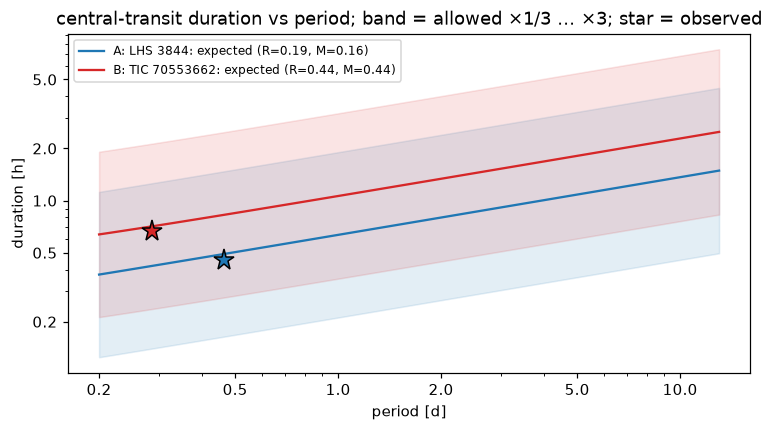

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
P = np.logspace(np.log10(0.2), np.log10(13), 100)
for tic, color in zip(STARS, ["C0", "C3"]):
    st, s = targets.loc[tic], search.loc[tic]
    T = np.array([expected_duration_h(x, st.rad, st.mass) for x in P])
    ax.fill_between(P, T * THRESH["dur_ratio_min"], T * THRESH["dur_ratio_max"], color=color, alpha=0.12)
    ax.plot(P, T, color=color, label=f"{STARS[tic]}: expected (R={st.rad:.2f}, M={st.mass:.2f})")
    ax.plot(s.period, s.duration_h, "*", ms=14, color=color, mec="k")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("period [d]"); ax.set_ylabel("duration [h]")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(plt.ScalarFormatter()); axis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks([0.2, 0.5, 1, 2, 5]); ax.set_xticks([0.2, 0.5, 1, 2, 5, 10])
ax.set_title("central-transit duration vs period; band = allowed ×1/3 … ×3; star = observed"); ax.legend(fontsize=8)

Both pass: B is an M-dwarf binary, so its eclipses have the duration expected for an M dwarf.
The duration test catches blends with *bigger* stars, not this kind of EB.

### 8.2 Planet radius

The transit depth gives the radius ratio: δ ≈ k² with k = Rp/R★. TLS reports `rp_rs`, which
already includes the limb-darkening correction (the stellar disk is darker at the edge, so a
planet near the centre blocks more light than average). Then $R_p = k\,R_\star$, and we
convert to Earth radii (1 R☉ = 109.1 R⊕).

**Threshold: Rp ≤ 1.5 R_J = 16.8 R⊕.** Nothing larger than ~2 R_J is a planet, and those
largest planets are *inflated* hot Jupiters around bright, hot stars. Giant planets around M
dwarfs receive little light and are ≤ ~1.2 R_J. Brown dwarfs and the smallest stars are all
~1 R_J, so the radius cannot separate those from planets (the other tests must). The plan's
"depth < 5 %" rule says the same thing, but expressed through the depth it depends on the
star's size. The radius is the physical quantity.

**Dilution.** If other stars' light falls in the aperture, a transit is diluted: the raw
observed depth is $\delta_{\rm obs} = \delta_{\rm true}/(1 + c)$, with c = TIC `contratio`.
Both of our light-curve products are already **deblended**: they subtract the expected
neighbour light so that a transit on the target keeps its true depth. SPOC PDCSAP records the
correction in the `CROWDSAP` header keyword. QLP does not say so in its headers, but the
known-objects walkthrough (`pipeline-6`, §6) shows it on a real case: a neighbour's 1 %
transit appears 3.4 % deep in a fainter star's QLP light curve, which only deblending can
do. So `rp_earth` needs no further correction. (An earlier version of this notebook also stored
`rp_earth * sqrt(1 + contratio)`, which corrected twice. It has been removed.)

In [19]:
def test_radius(s, star) -> dict:
    rp = s.rp_rs * star.rad * R_EARTH_PER_R_SUN  # light curves are already deblended
    return {"rp_earth": rp, "pass_radius": bool(rp <= THRESH["rp_earth_max"])}


pd.DataFrame({STARS[t]: test_radius(search.loc[t], targets.loc[t]) for t in STARS})

,A: LHS 3844,B: TIC 70553662
rp_earth,1.275004,19.924378
pass_radius,True,False


LHS 3844 b comes out at 1.3 R⊕, matching the published 1.30 R⊕. B's companion would be
20 R⊕ ≈ 1.8 R_J. That is not a planet around an M dwarf, so B fails its second hard test.

## 9. Stellar variability masquerading as transits

**The problem.** `detrend.py` divides by a biweight trend with a 0.5-day window. That
removes variability *slower* than ~1 day, and by design it keeps anything shorter (the
transits). Many M dwarfs are fast rotators with star spots, with rotation periods of a few
hours to a day, and some light curves contain pulsating stars blended in. A sinusoid with a
period of a few hours survives flattening, and TLS fits a "transit" into every minimum of it.
Such signals have high SDE, consistent depths, no odd/even difference, and pass most of
the tests above.

**The tool: the Lomb–Scargle periodogram.** For each trial frequency f it fits
$y(t) = A\sin(2\pi f t) + B\cos(2\pi f t) + C$ by least squares and reports the *power*,
the fraction of the variance explained by that sinusoid (0 to 1). It is the standard
periodogram for unevenly sampled data (Lomb 1976; Scargle 1982; VanderPlas 2018 is a good
practical review). We run it on the flattened flux **with the transits masked out**, so a
real transit cannot create its own power.

**The test.** Let $f_{\rm var}$ be the frequency of the highest periodogram peak and
$f = 1/P$ the TLS frequency. The signal is rejected if all three hold:

1. **The peak is real.** Its false-alarm probability (FAP, the chance that white noise alone
   produces a peak this high anywhere in the searched range; astropy computes it with the
   Baluev 2008 approximation) is below 10⁻³. Real light curves have red noise, which makes the
   FAP optimistic, so this is a minimum requirement, not a proof.
2. **It is a harmonic** of the TLS frequency: $|f_{\rm var} - n f| < 1/T$ or
   $|f - n f_{\rm var}| < 1/T$ for some n ≤ 10 (TLS fits a dip per cycle, or per n cycles),
   where T is the time baseline. **Why compare frequencies and not period ratios?** A
   periodogram cannot locate a peak more precisely than about one *resolution element*, 1/T in
   frequency. Over a 25-day sector that is 0.04 cycles/day. At P = 0.3 d that is a 1 %
   uncertainty in period, but at P = 2 d it is 8 %. A fixed relative tolerance on the period
   ratio is far too tight for long periods and too loose for short ones.
3. **It is strong enough to fake the dip**: its semi-amplitude is ≥ 15 % of the transit depth.

Each condition guards against a different mistake. Without (1), weak noise peaks that happen
to sit at a harmonic reject real planets. Without (3), a real planet on a mildly spotted star
is rejected. Without the frequency form of (2), obvious rotators slip through. All three
happened in the first full run (§12.1).

In [20]:
def test_variability(p) -> dict:
    s, t, y = p["s"], p["t"], p["y"]
    m = p["oot"]
    ls = LombScargle(t[m], y[m])
    fmin, fmax = 1 / 13, 1 / 0.02
    freq, power = ls.autopower(minimum_frequency=fmin, maximum_frequency=fmax, samples_per_peak=10)
    f_peak = freq[np.argmax(power)]
    fap = float(ls.false_alarm_probability(power.max(), minimum_frequency=fmin, maximum_frequency=fmax))
    model = ls.model(np.linspace(0, 1 / f_peak, 200), f_peak)
    amp = (model.max() - model.min()) / 2  # semi-amplitude, relative flux
    amp_frac = amp / (s.depth_ppm / 1e6)
    # harmonic matching in frequency, in units of the resolution 1/T
    T = t[m].max() - t[m].min()
    f = 1 / s.period
    cands = [(n, abs(f_peak - n * f)) for n in range(1, THRESH["var_harmonic_n_max"] + 1)]
    cands += [(-n, abs(f - n * f_peak)) for n in range(2, THRESH["var_harmonic_n_max"] + 1)]
    n_best, off = min(cands, key=lambda x: x[1])
    significant = fap < THRESH["var_fap_max"]
    harmonic = off * T < THRESH["var_harmonic_tol"]
    p["ls"] = (freq, power)  # kept for plotting only
    return {"var_period": 1 / f_peak, "var_power": float(power.max()), "var_fap": fap, "var_amp_ppm": amp * 1e6,
            "var_harmonic_n": n_best, "var_harmonic_offset": off * T, "var_amp_frac": amp_frac,
            "pass_variability": bool(not (significant and harmonic and amp_frac >= THRESH["var_amp_frac_max"])),
            "flag_variable_star": bool(significant and amp_frac >= THRESH["variable_amp_frac"])}


pd.DataFrame({STARS[t]: test_variability(prep[t]) for t in STARS})

,A: LHS 3844,B: TIC 70553662
var_period,0.298903,0.286364
var_power,0.00143,0.516563
var_fap,0.181044,0.0
var_amp_ppm,177.321868,9495.339674
var_harmonic_n,2,1
var_harmonic_offset,23.643018,0.027701
var_amp_frac,0.037345,0.045362
pass_variability,True,True
flag_variable_star,False,False


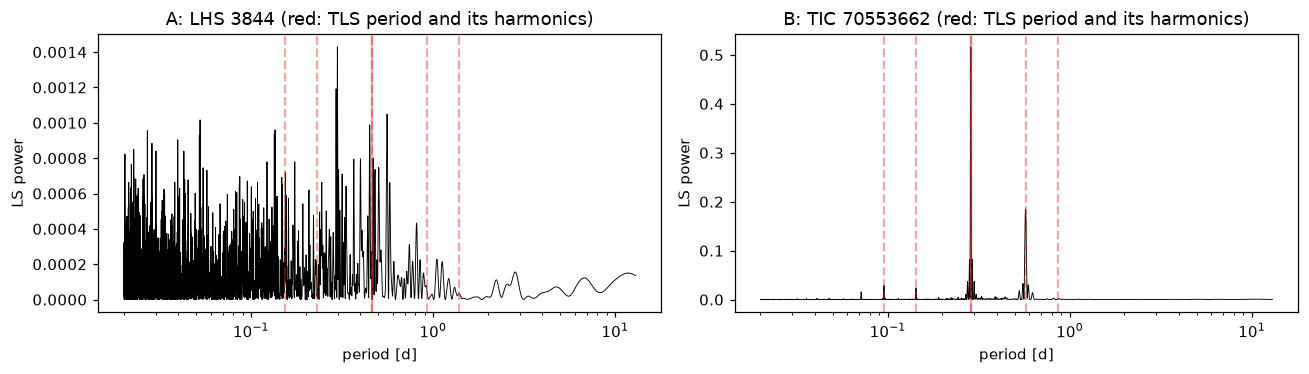

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, tic in zip(axes, STARS):
    freq, power = prep[tic]["ls"]; s = search.loc[tic]
    ax.plot(1 / freq, power, "k-", lw=0.6)
    for n in (1, 2, 3):
        ax.axvline(s.period * n, color="C3", alpha=0.4, ls="--" if n > 1 else "-")
        ax.axvline(s.period / n, color="C3", alpha=0.4, ls="--")
    ax.set_xscale("log"); ax.set_xlabel("period [d]"); ax.set_ylabel("LS power")
    ax.set_title(f"{STARS[tic]} (red: TLS period and its harmonics)")
plt.tight_layout()

A's periodogram is flat noise (power ~0.001, FAP far above 10⁻³). B has a strong peak at exactly the TLS period
(power ~0.5), and a second one at 2P = 0.573 d, the binary's true orbital period. That is the
out-of-eclipse modulation of the binary: tidally distorted stars and reflection. But its amplitude is only ~5 % of the 21 % eclipse depth, so this test
correctly says *the dips are not made of variability*. B is still rejected by the odd/even
and radius tests. This is a case where a test passes a false positive, which is why we need
many independent tests.

Examples that *this* test catches are in §12 (TIC 369586828, TIC 23817315, TIC 320263492).

## 10. Soft flags

These three do not enter `passes_all`. They are stored and shown in the report, because each
one either fires on real planets too often or is too noisy at low SNR to reject on its own.

### 10.1 Transit shape: U or V

A transit has four contact points: T1 (the planet's disk first touches the star's), T2
(fully inside), T3, T4. Between T2 and T3 the depth is roughly constant, so the transit has
a flat bottom (a U). If the companion is large compared with the star (EB), or the transit is
grazing, T2 and T3 never happen and the eclipse is a V.

We fit a **trapezoid** to the folded transit, with parameters centre, depth, total duration
$T_{14}$ and the flat-bottom fraction $f = T_{23}/T_{14}$ (1 = box, 0 = V). Flag
`v_shaped` if f < 0.3.

Why soft: grazing *planets* are V-shaped too, and for low-SNR signals the ingress/egress is
not resolved, so f is unconstrained (TOI-122 b, a real planet, gives f ≈ 0.2 in §12).

In [22]:
def trapezoid(x, x0, depth, t14, f):
    '''x and durations in hours. f = T23/T14, 1 = box, 0 = V.'''
    ax = np.abs(x - x0)
    t23 = f * t14
    y = np.ones_like(x)
    y[ax <= t23 / 2] = 1 - depth
    ingress = (ax > t23 / 2) & (ax < t14 / 2)
    y[ingress] = 1 - depth * (t14 / 2 - ax[ingress]) / ((t14 - t23) / 2 + 1e-12)
    return y


def test_shape(p) -> dict:
    s = p["s"]
    x = p["dt"] * 24
    sel = np.abs(x) < 3 * s.duration_h
    h = s.duration_h
    try:
        popt, _ = curve_fit(trapezoid, x[sel], p["y"][sel], p0=[0, s.depth_ppm / 1e6, h, 0.5],
                            bounds=([-h / 2, 0, 0.3 * h, 0], [h / 2, 1, 3 * h, 1]))
    except Exception:
        return {"trap_depth_ppm": np.nan, "trap_t14_h": np.nan, "trap_flat_frac": np.nan, "flag_v_shaped": False}
    p["trap"] = popt  # kept for plotting only
    return {"trap_depth_ppm": popt[1] * 1e6, "trap_t14_h": popt[2], "trap_flat_frac": popt[3],
            "flag_v_shaped": bool(popt[3] < THRESH["v_shape_max"])}


pd.DataFrame({STARS[t]: test_shape(prep[t]) for t in STARS})

,A: LHS 3844,B: TIC 70553662
trap_depth_ppm,4439.190427,226990.879523
trap_t14_h,0.553538,1.057423
trap_flat_frac,0.707263,0.253348
flag_v_shaped,False,True


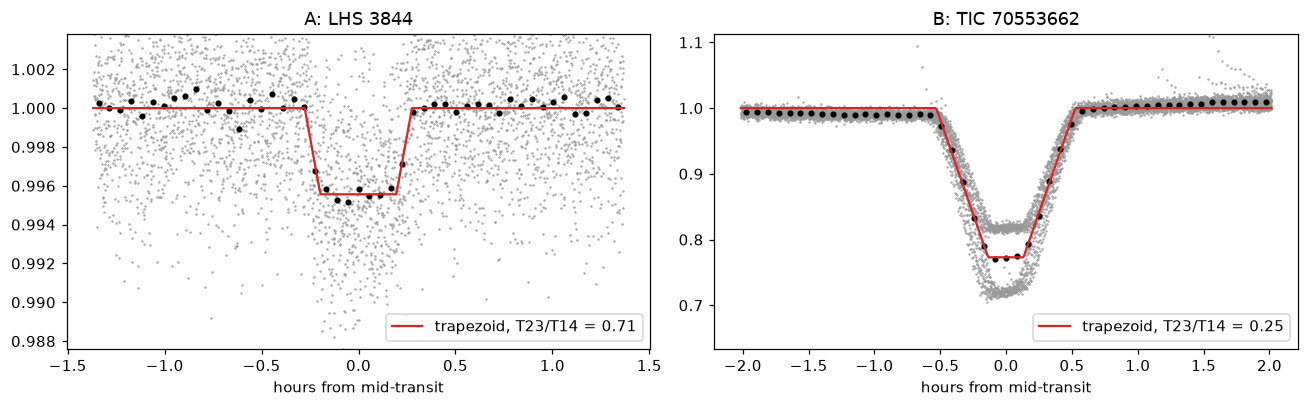

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, tic in zip(axes, STARS):
    p = prep[tic]; s = p["s"]
    x = p["dt"] * 24; sel = np.abs(x) < 3 * s.duration_h
    ax.plot(x[sel], p["y"][sel], ".", ms=1, color="0.6")
    bins = np.linspace(-3 * s.duration_h, 3 * s.duration_h, 50)
    idx = np.digitize(x[sel], bins)
    ax.plot(0.5 * (bins[1:] + bins[:-1]), [p["y"][sel][idx == i].mean() for i in range(1, len(bins))], "ok", ms=3)
    xx = np.linspace(bins[0], bins[-1], 500)
    ax.plot(xx, trapezoid(xx, *p["trap"]), "C3-", label=f"trapezoid, T23/T14 = {p['trap'][3]:.2f}")
    ax.set_title(STARS[tic]); ax.set_xlabel("hours from mid-transit"); ax.legend(loc="lower right")
    lo = np.percentile(p["y"][p["in_tr"]], 5); ax.set_ylim(lo - 0.3 * (1 - lo), 1 + 0.4 * (1 - lo))
plt.tight_layout()

A has a flat bottom (U). B is close to a V, and in B's case it is the *average* of two
different V-shaped eclipses.

### 10.2 Centroid motion during transit

TESS pixels are 21″, so the aperture of a faint M dwarf often contains other stars. If the
dip happens on a *neighbour*, then during the eclipse the neighbour fades and the light
centroid of the aperture **shifts away from it**. If the dip is on our star, the centroid
moves towards the neighbours instead, but only by (depth × their light fraction × distance).

We do not need pixel data for a first check: every light-curve file stores the flux-weighted
centroid per cadence (`MOM_CENTR1/2` in SPOC files, `SAP_X/SAP_Y` in QLP files). We match
those cadences to the flattened light curve, remove their slow drift with the same kind of
running filter (a 0.5-day median), and compare the mean in-transit centroid with the
out-of-transit median, in σ.

Why soft: a significant shift says *the light distribution changes during the dip*, not
*where* the source is. A deep on-target eclipse with a bright neighbour also produces one,
and finding the source position needs the pixel files (difference imaging, a later
milestone). In §12, every EB and variable shows a shift above 3σ, and the four planets are
all below 2.2σ.

In [24]:
def test_centroid(p, raw_file) -> dict:
    t = p["t"]
    d = fits.getdata(ROOT / raw_file, 1)
    names = d.columns.names
    cx, cy = ("MOM_CENTR1", "MOM_CENTR2") if "MOM_CENTR1" in names else ("SAP_X", "SAP_Y")
    tt = d["TIME"]
    idx = np.clip(np.searchsorted(tt, t), 0, len(tt) - 1)
    same = np.abs(tt[idx] - t) < 1e-4  # match cadences by time (< 9 s)
    shift, err = [], []
    for col in (cx, cy):
        v = d[col][idx].astype(float)
        g = same & np.isfinite(v)
        trend = wotan.flatten(t[g], v[g], method="median", window_length=0.5, return_trend=True)[1]
        r = v[g] - trend
        it, oo = p["in_tr"][g], p["oot"][g]
        r_ok = np.isfinite(r)
        it, oo, r = it & r_ok, oo & r_ok, np.where(r_ok, r, 0)
        shift.append(r[it].mean() - np.median(r[oo]))
        err.append(robust_std(r[oo]) / np.sqrt(it.sum()))
    total = float(np.hypot(*shift))
    sig = total / float(np.hypot(*err) / np.sqrt(2))
    return {"centroid_shift_px": total, "centroid_sigma": sig,
            "flag_centroid": bool(sig > THRESH["centroid_sigma_max"])}


pd.DataFrame({STARS[t]: test_centroid(prep[t], manifest.loc[t, "file_path"]) for t in STARS})

,A: LHS 3844,B: TIC 70553662
centroid_shift_px,0.000115,0.003202
centroid_sigma,0.545482,30.720274
flag_centroid,False,True


A: a shift of 10⁻⁴ pixels, 0.5σ, which is nothing. B: 30σ, but a tiny 0.003 px. B's
`contratio` is 0.04 (almost no neighbour light), so this is most likely the on-target deep
eclipse moving the centroid towards faint neighbours. That is why the flag is soft.

### 10.3 Contamination

`contratio` from the TIC is the flux from neighbours that falls in a nominal aperture,
divided by the star's flux. Above 0.5, a third of the light in the aperture is not our star.
Any signal could belong to a neighbour, and the planet radius is uncertain by $\sqrt{1+c}$.

In [25]:
def test_contamination(star) -> dict:
    c = float(star.contratio) if np.isfinite(star.contratio) else np.nan
    return {"contratio": c, "flag_contamination": bool(c > THRESH["contratio_max"])}


pd.DataFrame({STARS[t]: test_contamination(targets.loc[t]) for t in STARS})

,A: LHS 3844,B: TIC 70553662
contratio,0.010833,0.038109
flag_contamination,False,False


### 10.4 Variable star

`test_variability` (§9) also raises a soft flag, `variable_star`, when a *significant* modulation
(FAP < 10⁻³) reaches 30 % of the transit depth at **any** period, harmonic or not. A strongly
variable star can still host a planet, but its residual variability can also shape a dip at a
non-harmonic period, especially when several periods are present. The flag tells the human to
look at the raw light curve.

## 11. Putting it together: `vet_one()`

This is the shape of the function `vet.py` will run once per star. It is a pure function of
(search row, star row, flattened light curve, raw file, dump times), and it returns one flat
dict:

- every metric (`*_sigma`, `*_ppm`, `duration_ratio`, …),
- one boolean `pass_*` per **hard** test and `flag_*` per **soft** flag,
- `passes_all` = AND of all hard tests, `n_flags` = number of soft flags raised,
- `failed`: names of the failed hard tests in one string, for quick reading.

**Ranking.** The plan suggests "SDE × passes". We sort by `passes_all` (passing first), then
`n_flags` (fewest warnings first), then SNR. We use SNR rather than SDE because our SNR is
β-corrected and is a property of the signal itself. SDE depends on how noisy *the rest of*
the periodogram is.

In [26]:
HARD = ["sde", "snr", "n_transits", "grid_edge", "single_event", "momentum_dump", "data_edges", "transit_noise",
        "odd_even", "secondary", "duration", "radius", "variability"]
SOFT = ["v_shaped", "centroid", "contamination", "variable_star"]


def vet_one(tic_id: int, dumps: np.ndarray) -> dict:
    s, star = search.loc[tic_id], targets.loc[tic_id]
    row = {"tic_id": tic_id, "SDE": s.SDE, "snr_tls": s.snr, "period": s.period, "depth_ppm": s.depth_ppm,
           "duration_h": s.duration_h}
    row.update(test_search_stats(s))
    p = prepare(tic_id)
    p["pt"] = per_transit(p)
    row.update(beta=p["noise"]["beta"], n_transits_used=len(p["pt"]), snr=combine(p["pt"])[2])
    row.update(test_single_event(p))
    row.update(test_momentum_dumps(p, dumps))
    row.update(test_data_edges(p))
    row.update(test_transit_noise(p))
    row.update(test_odd_even(p))
    row.update(test_secondary(p))
    row.update(test_duration(s, star))
    row.update(test_radius(s, star))
    row.update(test_variability(p))
    row.update(test_shape(p))
    row.update(test_centroid(p, manifest.loc[tic_id, "file_path"]))
    row.update(test_contamination(star))
    row["passes_all"] = all(row[f"pass_{k}"] for k in HARD)
    row["n_flags"] = sum(row[f"flag_{k}"] for k in SOFT)
    row["failed"] = ",".join(k for k in HARD if not row[f"pass_{k}"])
    row["flags"] = ",".join(k for k in SOFT if row[f"flag_{k}"])
    return row


vetted = pd.DataFrame([vet_one(t, DUMPS) for t in STARS]).set_index("tic_id")
vetted.T.rename(columns=STARS)

tic_id,A: LHS 3844,B: TIC 70553662
SDE,32.313159,44.456002
snr_tls,32.39437,1037.084779
period,0.462953,0.28627
depth_ppm,4748.151035,209324.630642
duration_h,0.456135,0.67169
pass_sde,True,True
pass_snr,True,True
pass_n_transits,True,True
pass_grid_edge,True,True
beta,1.084993,4.281343


That table is **one row of `data/search/sector_104_vetted.parquet` per star**, transposed
here for reading. A passes all 13 hard tests with no flags. B fails `odd_even`, `secondary`
and `radius`, and raises the `v_shaped` and `centroid` flags.

## 12. Validation: known planets must pass, known impostors must fail

A vetting pipeline is only trustworthy if it is checked against objects whose nature we
already know. Two lists:

- **Confirmed planets in the sector-104 target list** (the same ones the search
  walkthrough's checklist used): LHS 3844 b, TOI-177 b, TOI-134 b, TOI-122 b. Every hard test
  they fail is a test that would also throw away a new planet.
- **Impostors** from the top of the SDE ranking, whose nature is obvious once you plot them
  (the gallery we looked at while preparing this notebook): deep EBs, an EB at half period,
  an eccentric EB, and three variable stars.

The ✗ marks which test rejected each one.

In [27]:
KNOWN_PLANETS = {410153553: "LHS 3844 b", 262530407: "TOI-177 b", 234994474: "TOI-134 b", 231702397: "TOI-122 b"}
IMPOSTORS = {70553662: "EB at P/2", 316096209: "deep EB", 371997949: "eccentric EB", 425864141: "EB (2 eclipses in fold)",
             369586828: "variable (7 dips per fold)", 23817315: "spotted rotator", 320263492: "variable (sinusoid, P = 2 P_var)"}

val = pd.DataFrame([vet_one(t, DUMPS) for t in {**KNOWN_PLANETS, **IMPOSTORS}]).set_index("tic_id")
val.insert(0, "what", pd.Series({**KNOWN_PLANETS, **IMPOSTORS}))
mark = lambda b: "✓" if b else "✗"
grid = val[["what", "SDE", "snr"]].round(1).copy()
for k in HARD:
    grid[k] = val[f"pass_{k}"].map(mark)
for k in SOFT:
    grid["⚑" + k] = val[f"flag_{k}"].map(lambda b: "⚑" if b else "")
grid["passes_all"] = val["passes_all"]
grid

,what,SDE,snr,sde,n_transits,grid_edge,single_event,momentum_dump,data_edges,transit_noise,odd_even,secondary,duration,radius,variability,⚑v_shaped,⚑centroid,⚑contamination,⚑variable_star,passes_all
tic_id,,,,,,,,,,,,,,,,,,,,
410153553,LHS 3844 b,32.3,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,,,,,True
262530407,TOI-177 b,19.4,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,,,,,True
234994474,TOI-134 b,19.4,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,,,,,True
231702397,TOI-122 b,10.2,✗,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,⚑,,,,False
70553662,EB at P/2,44.5,✓,✓,✓,✓,✓,✓,✓,✓,✗,✗,✓,✗,✓,⚑,⚑,,,False
316096209,deep EB,59.7,✓,✓,✓,✓,✓,✓,✓,✓,✗,✓,✓,✗,✓,⚑,⚑,,,False
371997949,eccentric EB,21.4,✓,✓,✓,✓,✓,✓,✓,✗,✗,✗,✓,✓,✓,⚑,⚑,,,False
425864141,EB (2 eclipses in fold),35.6,✓,✓,✓,✓,✓,✓,✓,✓,✓,✗,✓,✓,✗,⚑,⚑,,,False
369586828,variable (7 dips per fold),26.2,✓,✓,✓,✓,✓,✓,✓,✓,✓,✗,✗,✓,✗,⚑,⚑,,⚑,False


Reading the grid:

- **LHS 3844 b, TOI-177 b and TOI-134 b pass everything.** TOI-134 b is only ~600 ppm deep,
  near our sensitivity limit, and still passes.
- **TOI-122 b fails `snr`.** In this sector its TLS SNR is 5.6: four transits of a 4,800 ppm
  planet on a noisy star. This is not a bug. It is the threshold doing its job, and it shows
  the trade-off every survey makes: SNR ≥ 7 rejects most noise, and also the weakest real
  planets. Lowering it would recover TOI-122 b and let in many more noise signals. The right
  value is decided by **injection/recovery** (plan §6), not by one star. Because every metric
  is stored, changing the threshold later costs nothing.
- **Every impostor is rejected, almost always by more than one test.** EBs fall to
  `radius`, `odd_even` and `secondary`. The variables fall to `variability` (and
  `secondary`, when the sinusoid also dips at phase 0.5).
- **One exception: the spotted rotator TIC 23817315 is caught *only* by `variability`.**
  Its secondary scan reaches 3.2σ, below the 5σ threshold. That makes `variability`
  load-bearing: if you loosen it (a larger `var_amp_frac_max`, a smaller harmonic tolerance),
  check this star again. The soft flags (V shape, 78σ centroid shift) would still make a
  human suspicious.
- TOI-122 b also raises the `v_shaped` flag: with only four noisy transits the trapezoid fit
  cannot resolve the ingress, which is why shape is a flag and not a test.
- **TOI-177 b shows why the variability test needs all three conditions** (§9). Its star has
  a *significant* periodogram peak (FAP ≈ 0) at exactly a harmonic of the planet's period
  (offset 0.001 resolution elements), but the modulation is only 7 % of the transit depth.
  Conditions 1 and 2 alone would have rejected a confirmed planet. The amplitude condition
  saves it.

Let's look at which metric values drove those decisions, side by side:

In [28]:
val[["what", "beta", "odd_even_sigma", "secondary_snr", "secondary_phase", "duration_ratio", "rp_earth",
     "var_fap", "var_harmonic_offset", "var_amp_frac", "trap_flat_frac", "centroid_sigma", "contratio", "failed"]].round(3)

,what,beta,odd_even_sigma,secondary_snr,secondary_phase,duration_ratio,rp_earth,var_fap,var_harmonic_offset,var_amp_frac,trap_flat_frac,centroid_sigma,contratio,failed
tic_id,,,,,,,,,,,,,,
410153553,LHS 3844 b,1.085,0.321,1.108,0.372,0.873,1.275,0.181,23.643,0.037,0.707,0.545,0.011,
262530407,TOI-177 b,1.653,2.616,3.097,0.606,0.650,1.919,0.000,0.001,0.074,0.684,0.771,0.013,
234994474,TOI-134 b,1.000,0.179,1.766,0.375,0.799,1.472,0.448,0.027,0.064,0.859,1.024,0.003,
231702397,TOI-122 b,1.000,1.310,2.866,0.689,0.523,2.280,0.714,254.095,0.074,0.220,2.145,0.009,snr
70553662,EB at P/2,4.281,32.439,9.093,0.842,0.657,19.924,0.000,0.028,0.045,0.253,30.720,0.038,"odd_even,secondary,radius"
316096209,deep EB,1.300,12.022,3.269,0.170,0.541,18.647,0.000,0.059,0.003,0.142,195.166,0.153,"odd_even,radius"
371997949,eccentric EB,1.000,205.327,153.900,0.559,0.546,16.414,0.000,1.506,0.011,0.283,3.375,0.036,"transit_noise,odd_even,secondary"
425864141,EB (2 eclipses in fold),1.944,0.379,74.772,0.500,0.538,9.536,0.000,0.007,0.265,0.162,50.376,0.036,"secondary,variability"
369586828,variable (7 dips per fold),2.106,0.417,26.522,0.500,0.306,5.724,0.000,0.093,0.554,0.112,26.783,0.064,"secondary,duration,variability"


### 12.1 What the first full run taught us (vetting v1 → v2)

The tests above are the **second** version (plus one more test added after the second review,
`transit_noise`). The first version was run on the whole sector, and
two independent checks showed where it was wrong:

**Injection-recovery** (notebook 8) injects synthetic planets into real light curves and
counts how many survive. In its first 132 injections, 8 correctly detected planets were
rejected by `single_event`, and all of them had exactly two transits. The survival rule
required ≥ 2 transits *left* after dropping the strongest one. A 2-transit signal always kept
just 1, so **every planet with P ≳ 8 d was rejected**. Now `single_event` needs only 1 left
(§5.3).

**Reading the report** (notebook 7, `docs/REVIEW_sector104.md`): each of the 32 "new"
candidates was looked at by eye. Recurring failure modes:

| what we saw | example | v1 test that missed it | v2 fix |
|---|---|---|---|
| "transits" at segment starts, after gaps, just before dumps | TIC 119624569, both transits 0.2–0.3 d before a dump | dump window ±0.1 d; no edge test | `data_edges` test; dump window ±0.25 d (§5.3) |
| a transit in a stretch of strong scattered light counted as significant | TIC 49143293 | global σ for every transit | local σ per transit (§5.1) |
| obvious rotators passed | TIC 32355300 (P_var 2.11 d, TLS 2.09 d: 0.7 % off) | period ratio within 0.5 % | harmonic match in frequency, within 1/T (§9) |
| a clean transit rejected as "variability" | TIC 161313862 (peak power 0.003, FAP ~2 %) | any peak, however weak | peak must have FAP < 10⁻³ (§9) |
| bursts of scatter inside a few transit windows (second review) | TIC 394134586 | nothing looked at in-transit scatter | `transit_noise` test (§5.3) |

The general lesson: **thresholds and tests are hypotheses.** Injection-recovery measures how
many real planets a test throws away (completeness), and looking at what survives measures
what it lets through (purity). Neither can be judged from the code alone.

## 13. The vetting sheet: one figure per candidate

Numbers decide, but a human always looks before believing. This is the kind of page
`report.py` (step 7) will produce for every surviving candidate: the light curve, the
per-transit depths with the momentum dumps, the fold, odd vs even, the secondary scan and the
test summary. It reuses the pieces above.

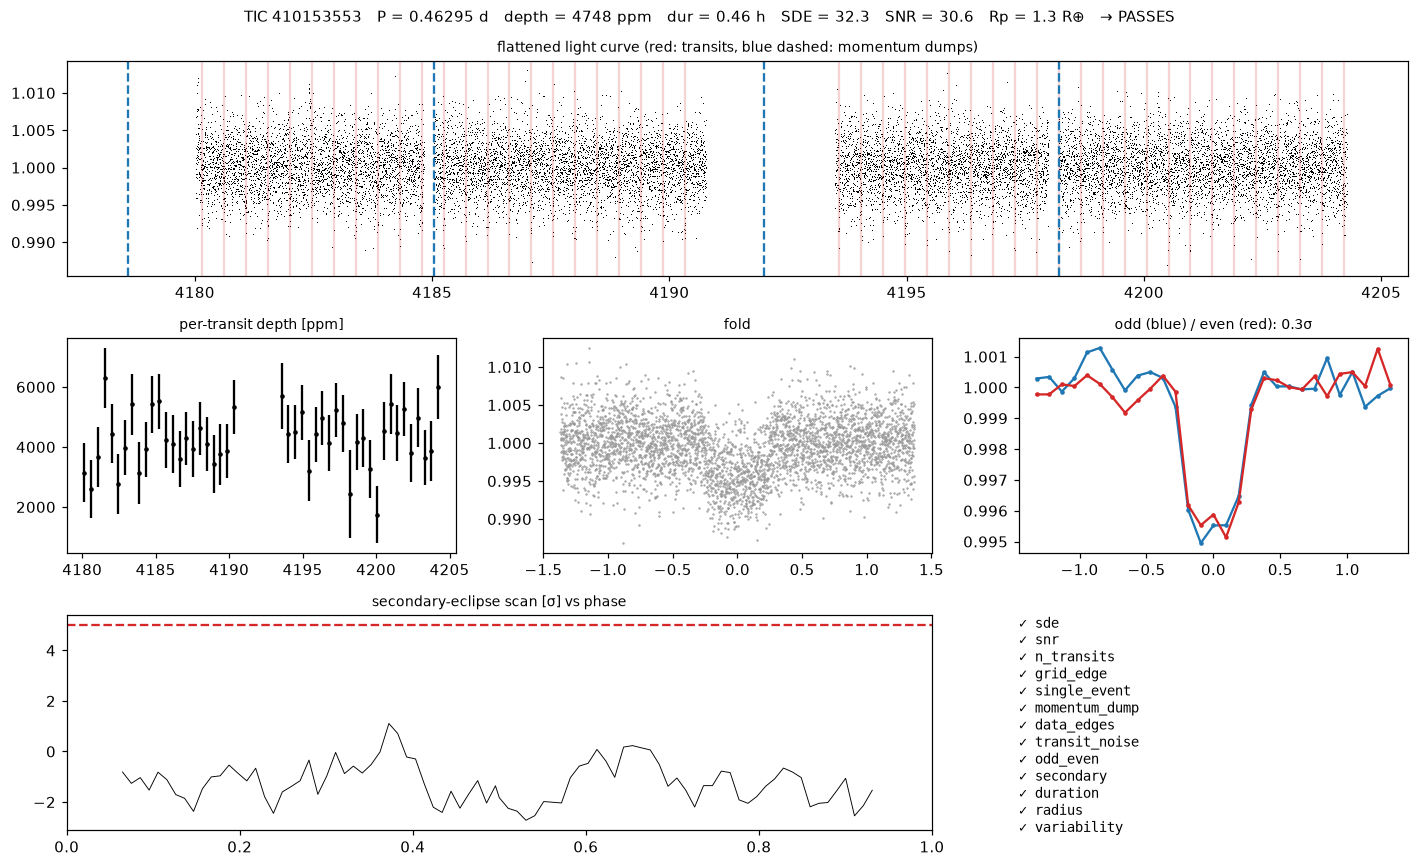

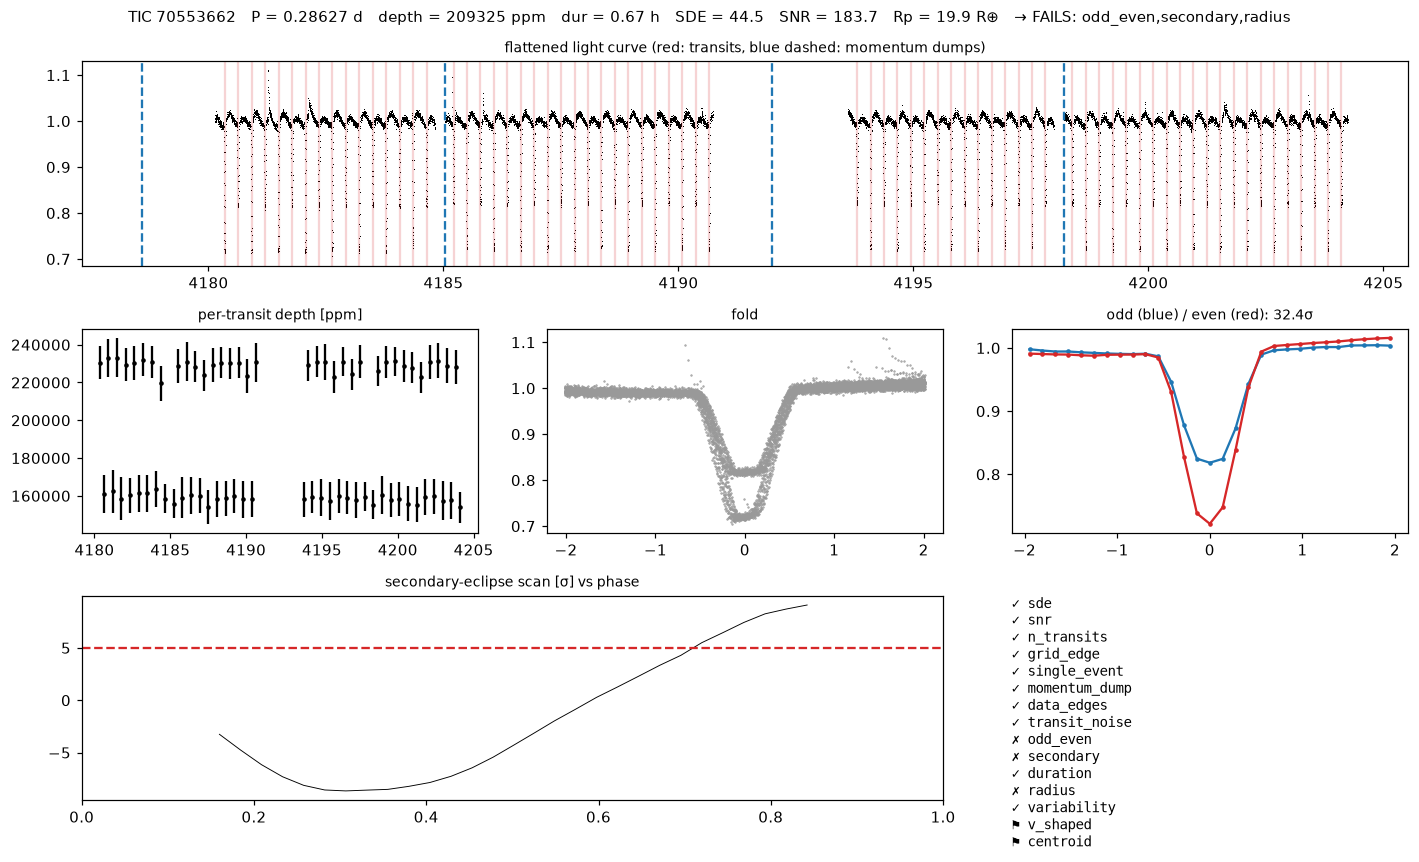

In [29]:
def vetting_sheet(tic_id: int, row: dict):
    p = prepare(tic_id); p["pt"] = per_transit(p); s = p["s"]
    test_secondary(p)
    fig = plt.figure(figsize=(13, 8))
    gs = fig.add_gridspec(3, 3)
    status = "PASSES" if row["passes_all"] else f"FAILS: {row['failed']}"
    fig.suptitle(f"TIC {tic_id}   P = {s.period:.5f} d   depth = {s.depth_ppm:.0f} ppm   dur = {s.duration_h:.2f} h   "
                 f"SDE = {s.SDE:.1f}   SNR = {row['snr']:.1f}   Rp = {row['rp_earth']:.1f} R⊕   → {status}", fontsize=10)
    ax = fig.add_subplot(gs[0, :])
    ax.plot(p["t"], p["y"], ",k")
    for tm in p["pt"].t_mid: ax.axvline(tm, color="C3", alpha=0.2)
    for td in DUMPS: ax.axvline(td, color="C0", ls="--")
    ax.set_title("flattened light curve (red: transits, blue dashed: momentum dumps)", fontsize=9)
    ax = fig.add_subplot(gs[1, 0])
    ax.errorbar(p["pt"].t_mid, p["pt"].depth * 1e6, p["pt"].err * 1e6, fmt="o", ms=2, color="k")
    ax.set_title("per-transit depth [ppm]", fontsize=9)
    x = p["dt"] * 24; sel = np.abs(x) < 3 * s.duration_h
    epoch = np.round((p["t"] - s.T0) / s.period).astype(int)
    ax = fig.add_subplot(gs[1, 1])
    ax.plot(x[sel], p["y"][sel], ".", ms=1, color="0.6"); ax.set_title("fold", fontsize=9)
    ax = fig.add_subplot(gs[1, 2])
    for parity, c in [(1, "C0"), (0, "C3")]:
        m = sel & (epoch % 2 == parity)
        bins = np.linspace(-3 * s.duration_h, 3 * s.duration_h, 30); idx = np.digitize(x[m], bins)
        ax.plot(0.5 * (bins[1:] + bins[:-1]), [p["y"][m][idx == i].mean() for i in range(1, len(bins))], "o-", ms=2, color=c)
    ax.set_title(f"odd (blue) / even (red): {row['odd_even_sigma']:.1f}σ", fontsize=9)
    ax = fig.add_subplot(gs[2, 0:2])
    sc = p["secondary_scan"]; ax.plot(sc[:, 0], sc[:, 1], "k-", lw=0.6)
    ax.axhline(THRESH["secondary_snr_max"], color="C3", ls="--"); ax.set_xlim(0, 1)
    ax.set_title("secondary-eclipse scan [σ] vs phase", fontsize=9)
    ax = fig.add_subplot(gs[2, 2]); ax.axis("off")
    lines = [f"{'✓' if row[f'pass_{k}'] else '✗'} {k}" for k in HARD] + [f"⚑ {k}" for k in SOFT if row[f"flag_{k}"]]
    ax.text(0, 1, "\n".join(lines), va="top", family="monospace", fontsize=9)
    plt.tight_layout()


for tic in STARS:
    vetting_sheet(tic, vetted.loc[tic].to_dict())

## 14. Checklist for writing `src/vet.py`

Follow the structure of `detrend.py` / `search.py`: module docstring with usage, `DATA_DIR`
from `.env`, a `VetRow` dataclass, `_worker_logging()`, `vet_one()`, `vet_sector()`,
`main()` with argparse.

**Inputs**

- `data/search/sector_{N}.parquet` (rows with `status == "ok"`): ephemeris, depth, duration,
  `rp_rs`, SDE/snr, counts, `period_max`, `period_unc`.
- `data/targets/sector_{N}.parquet`: `rad`, `mass`, `contratio`.
- `data/targets/sector_{N}_detrend.parquet` → `file_path` of the flattened light curve.
- `data/targets/sector_{N}_manifest.parquet` → `file_path` of the raw FITS (centroids,
  momentum dumps).
- Optionally the pass-2 table (`data/search/pass2/…`), vetted the same way into its own file.

**Once per sector:** `momentum_dumps()` from ~20 raw files. Log them, and store them in the
output parquet's metadata or in a small side file so `report.py` can draw them.

**`vet_one(tic_id, search_row, star_row, flat_file, raw_file, dumps) -> VetRow`**

- Group A (§4) first, from the search row alone.
- **Pre-filter**: if `pass_sde` *and* `pass_n_transits` are both false, skip the light-curve
  tests (leave NaN, `status="prefiltered"`). The plan says "no early exit", and the test results
  are still recorded. But opening ~4,000 light curves of pure noise to compute odd/even
  depths of nothing wastes time. A CLI flag `--no-prefilter` runs everything.
- Then `prepare()` (noise model with β) → per-transit table → the hard tests of §5–9 and
  the soft flags of §10, each in its own small function with its own `try/except`, so one
  failing test (e.g. a trapezoid fit that does not converge) gives NaN for that test, not
  an error for the star.
- Conventions: a test that *cannot be evaluated* (no odd or no even transits, no phases left
  for the secondary scan) **passes**. Absence of evidence is not a rejection, and the
  transit-count test already covers the "too few transits" case.
- Outer `try/except Exception` → `status="error"` + message, like the other steps.

**`vet_sector(sector, n_jobs, limit, force, …)`**

- `joblib.Parallel` across stars. Every test is NumPy on ~10⁴ points, plus one Lomb–Scargle and
  one FITS read, so it should take well under a second per star.
- Output `data/search/sector_{N}_vetted.parquet`: one row per star with all metrics, all
  `pass_*`/`flag_*`, `passes_all`, `n_flags`, `failed`, `flags`, sorted by the ranking of §11.
- Log the **funnel** (how many stars survive each hard test in sequence) and the list of
  `passes_all` stars with period, depth, Rp and flags.
- `THRESH` as a module-level dict, with CLI overrides for the ones you will tune
  (`--sde-min`, `--snr-min`, `--odd-even-max`, `--secondary-max`).

**Sanity checks before trusting the output**

1. The four known planets of §12: three pass, and TOI-122 b fails only `snr` (unless you
   lower that threshold). In the full sector, all 8 confirmed planets must pass.
2. The impostors of §12 all fail.
3. Look at the vetting sheet of *every* `passes_all` star. Expect a few tens. For each one,
   decide by eye whether you agree, and note the cases where you do not. A pattern of
   disagreement is a missing test.
4. Later, injection/recovery: inject transits into real light curves, run steps 3–5, and
   measure how many injected planets survive *vetting* (not just detection). The thresholds
   above should be revisited with that number.

**Not done here, and where it belongs**

- *Ephemeris matching across stars*: the same period and phase on two stars a few pixels
  apart means one contaminates the other. It needs sky positions and catalog cross-matching, so
  it fits in `known.py` (plan §8, "neighbour_match").
- *Pixel-level centroids / difference images* (TPF), *statistical validation* (TRICERATOPS),
  and the comprehensive test suite of *LEO-vetter* (Kunimoto et al.), which we can run on
  the final short list as a cross-check.